# Practical 1: Text classification with SNLI

Can simple token features recognise entailment, neutral statements and
contradictions? We compare **indicators, unigram counts and pure bigram counts**
with **logistic regression, a one-hidden-layer MLP and a two-hidden-layer MLP**.

The notebook follows the short explanation → code → example → result pattern of
[the course practical](https://github.com/S-Chaudhuri/uva_nlp1_2025/blob/main/NLP1_2025_Practical_2_%28student%29.ipynb).
Our task and assessment requirements come from [Project 1](project.ipynb).

Three experiments are complete:

| Experiment | Training pool | Evaluation | What it establishes |
| --- | ---: | --- | --- |
| Baseline comparison | 60,005 rows | Five grouped folds × three split seeds | CV/Bayesian comparisons of fixed recipes |
| Short joint search | 100,001 rows | All 9,839 eligible validation rows | Best of three tested recipes per system, one model seed |
| Final frozen fit | 559,164 train+validation rows | 9,824 official test rows | One selected pipeline, five fixed epochs |

The final fit and one-time official test evaluation are complete: **74.58% accuracy** on 9,824 test pairs. The 50-case error review and frozen recipe are in section 9; final graphs are in section 10.
Run All reads the completed experiments, redraws the final graphs and runs a small teaching example.
Training switches default to false; any new search/CV invocation is capped at
15 minutes. All custom code used here is defined in these cells. The separate
[details notebook](practical_1_details.ipynb) preserves the original cache/resume
machinery and historical experiments; it is never imported or executed here.

## 1. Setup

Use the repository's `.venv` kernel. Standard libraries and installed packages
are imports; the local Python helper modules are not used by this notebook.

In [1]:
from pathlib import Path
from collections import Counter
from contextlib import contextmanager
from copy import deepcopy
from itertools import chain
from array import array
from time import perf_counter
import hashlib
import json
import random
import re
import signal
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import sparse
from scipy.stats import t
import torch
from torch import nn
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold
from datasets import load_dataset, load_from_disk, DatasetDict, ClassLabel, disable_progress_bars
from tokenizers import Tokenizer, normalizers
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Metaspace
from IPython.display import display
import joblib

disable_progress_bars()

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "part1/project.ipynb").exists())
PART1 = ROOT / "part1"
OUTPUT = PART1 / "results/project1"
BASE = json.loads((PART1 / "configs/snli_project1_frozen_bigram.json").read_text())
SEARCH = json.loads((PART1 / "configs/snli_tuning.json").read_text())
LABELS = ["entailment", "neutral", "contradiction"]
REPRESENTATIONS = ["indicators", "unigram_counts", "bigram_counts"]
CLASSIFIERS = ["logistic", "mlp_one_hidden", "mlp_two_hidden"]
PROBABILITY_COLUMNS = [f"p_{name}" for name in LABELS]
KEYS = ["repetition", "seed", "fold"]
NEW_RUNS = OUTPUT / "streamlined"
MAX_SECONDS = 15 * 60


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)
print("Repository:", ROOT)
print("PyTorch:", torch.__version__, "| device: CPU | model seed: 0")

Repository: /home/borisv/nlp1-student-gp57
PyTorch: 2.15.0+cpu | device: CPU | model seed: 0


## 2. The data

SNLI pairs a **premise** with a **hypothesis**. Entailment means the hypothesis
follows from the premise, contradiction means it conflicts, and neutral means
neither follows. We retain labels `[0, 1, 2]` in that order, remove invalid labels
and blank text, and preserve source row IDs. Cached Arrow files are the downloaded
dataset; loading them offline is expected.

In [3]:
def load_snli():
    directory = PART1 / "data/snli" / BASE["dataset"]["revision"] / "cleaned-v1"
    if directory.exists():
        data = load_from_disk(str(directory))
    else:
        raw = load_dataset(BASE["dataset"]["repo_id"], revision=BASE["dataset"]["revision"],
                           cache_dir=str(PART1 / "data/huggingface"))
        cleaned = {}
        for split, rows in raw.items():
            rows = rows.map(lambda row, i: {"source_row": i, "source_split": split,
                                            "example_id": f"{split}:{i}"}, with_indices=True)
            cleaned[split] = rows.filter(lambda row: row["label"] in (0, 1, 2)
                and all(isinstance(row[name], str) and row[name].strip()
                        for name in ("premise", "hypothesis")))
        data = DatasetDict(cleaned)
        directory.parent.mkdir(parents=True, exist_ok=True)
        data.save_to_disk(str(directory))
    for split in ("train", "validation", "test"):
        label = data[split].features["label"]
        assert isinstance(label, ClassLabel) and label.names == LABELS
        assert len(data[split]) > 0
    return data


data = load_snli()
display(pd.DataFrame({"split": list(data), "clean_rows": [len(data[s]) for s in data]}))
examples = data["train"].select_columns(["premise", "hypothesis", "label"]).to_pandas()
display(examples.groupby("label", sort=True).head(1).assign(label=lambda x: x.label.map(dict(enumerate(LABELS)))))

,split,clean_rows
0,train,549367
1,validation,9842
2,test,9824


,premise,hypothesis,label
0,A person on a horse jumps over a broken down a...,A person is training his horse for a competition.,neutral
1,A person on a horse jumps over a broken down a...,"A person is at a diner, ordering an omelette.",contradiction
2,A person on a horse jumps over a broken down a...,"A person is outdoors, on a horse.",entailment


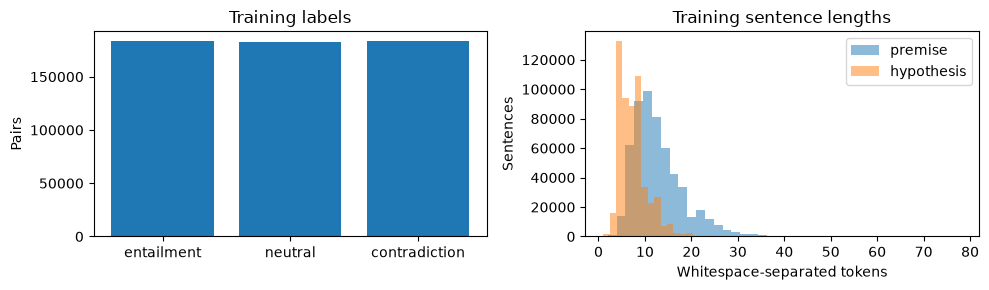

In [4]:
counts = examples.label.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar(LABELS, counts)
axes[0].set(title="Training labels", ylabel="Pairs")
for name in ("premise", "hypothesis"):
    axes[1].hist(examples[name].str.split().str.len(), bins=40, alpha=.5, label=name)
axes[1].set(title="Training sentence lengths", xlabel="Whitespace-separated tokens", ylabel="Sentences")
axes[1].legend()
plt.tight_layout()
plt.show()
del examples

The cleaned source splits contain **549,367 / 9,842 / 9,824** rows. Labels are
close to balanced. Accuracy is our primary metric; NLL assesses the probabilities
and macro-F1 checks performance across classes. Lengths above describe whitespace
words, not the BPE units used by the classifiers.

Several hypotheses share the same premise. We keep exact-premise groups together
in CV and exclude training premises present in the official holdouts. Validation
premises also present in test are excluded from development selection. These
rules preserve the original official splits and reserve test for the final score.

In [5]:
def make_pools(data):
    """Return metadata selections; test text is used only for premise exclusions."""
    frames = {}
    for split in ("train", "validation", "test"):
        columns = ["example_id", "source_row", "source_split", "premise"]
        frame = data[split].select_columns(columns).to_pandas()
        frame.insert(0, "clean_index", np.arange(len(frame)))
        frames[split] = frame
    validation_premises = set(frames["validation"].premise)
    test_premises = set(frames["test"].premise)
    train = frames["train"].loc[~frames["train"].premise.isin(validation_premises | test_premises)].copy()
    validation = frames["validation"].loc[~frames["validation"].premise.isin(test_premises)].copy()
    for frame in (train, validation):
        frame["premise_group"] = frame.premise.map(lambda text: hashlib.sha256(text.encode()).hexdigest())
        frame.drop(columns="premise", inplace=True)
        frame.reset_index(drop=True, inplace=True)
    train["label"] = np.asarray(data["train"]["label"])[train.clean_index]
    assert set(train.premise_group).isdisjoint(validation.premise_group)
    return train, validation


def sample_groups(frame, target_rows, seed):
    """Shuffle whole groups independently of labels; retain original row order."""
    if not 1 <= target_rows <= len(frame):
        raise ValueError("Sampling target must be inside the eligible pool.")
    sizes = frame.groupby("premise_group", sort=True).size()
    shuffled = sizes.iloc[np.random.default_rng(seed).permutation(len(sizes))]
    n_groups = np.searchsorted(shuffled.cumsum(), target_rows) + 1
    return frame.loc[frame.premise_group.isin(shuffled.index[:n_groups])].reset_index(drop=True)


def select_text(data, rows, split="train"):
    return data[split].select(rows.clean_index.tolist()).select_columns(
        ["premise", "hypothesis", "label", "example_id"]).to_pandas()


eligible_train, eligible_validation = make_pools(data)
cv_rows = sample_groups(eligible_train, 60000, seed=0)
search_rows = sample_groups(eligible_train, 100000, seed=57)
display(pd.DataFrame({"pool": ["eligible train", "eligible validation", "baseline CV", "short search"],
                     "rows": [len(eligible_train), len(eligible_validation), len(cv_rows), len(search_rows)]}))

/tmp/ipykernel_94298/4157381256.py:15: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.drop(columns="premise", inplace=True)
/tmp/ipykernel_94298/4157381256.py:16: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.reset_index(drop=True, inplace=True)
/tmp/ipykernel_94298/4157381256.py:15: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.drop(columns="premise", inplace=True)
/tmp/ipykernel_94298/4157381256.py:16: Pandas4Warning: The inplace keyword in DataFrame.res

,pool,rows
0,eligible train,549253
1,eligible validation,9839
2,baseline CV,60005
3,short search,100001


## 3. Evaluation design

The baseline uses five `StratifiedGroupKFold` folds and split seeds `[0, 3, 5]`.
All systems share the same partitions, with one held-out prediction per row per
repetition. Each fold learns a fresh BPE vocabulary and bigram inventory from its
training data. Coordinates need not agree across independent fitted pipelines.

The baseline fixed all model settings and **three neural epochs** before CV.
It did **not** select epochs using outer held-out scores. A small earlier pilot
motivated that schedule; it was an engineering choice, not exhaustive tuning.
The later 27-observation search uses official validation and has no new CV scores.

In [6]:
def grouped_folds(rows, n_splits=5, seeds=(0, 3, 5)):
    result = rows.copy()
    for seed in seeds:
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        fold_ids = np.full(len(rows), -1)
        for fold, (_, heldout) in enumerate(splitter.split(np.zeros(len(rows)), rows.label,
                                                          groups=rows.premise_group)):
            fold_ids[heldout] = fold
        result[f"fold_seed_{seed}"] = fold_ids
        assert result.groupby("premise_group")[f"fold_seed_{seed}"].nunique().eq(1).all()
    return result


def local_path(value):
    """Resolve saved local paths if this checkout has moved."""
    path = Path(value)
    if path.exists():
        return path
    if "part1" in path.parts:
        return ROOT.joinpath(*path.parts[path.parts.index("part1"):])
    return ROOT / path


def read_json(path):
    return json.loads(Path(path).read_text())


def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def notebook_code_hash():
    """Ignore displayed outputs and the two opt-in training switches."""
    cells = read_json(PART1 / "practical_1.ipynb")["cells"]
    source = "\n".join(line for cell in cells if cell["cell_type"] == "code"
        for line in "".join(cell["source"]).splitlines() if not line.startswith("RUN_"))
    return hashlib.sha256(source.encode()).hexdigest()


def check_files(directory, hashes):
    for name, expected in hashes.items():
        assert file_hash(Path(directory) / name) == expected, f"Changed artifact: {name}"


cv_pointer = read_json(OUTPUT / "manifests/cross_validation.json")
cv_directory = local_path(cv_pointer["manifest_path"]).parent
cv_manifest = read_json(cv_directory / "manifest.json")
check_files(cv_directory, cv_manifest["artifact_sha256"])
assert cv_manifest["status"] == "complete" and cv_manifest["specification"]["configuration"] == BASE
protocol = read_json(local_path(cv_manifest["protocol_manifest"]))
folds = pd.read_parquet(local_path(cv_manifest["protocol_manifest"]).parent / "fold_assignments.parquet")
for column in ("clean_index", "example_id", "source_row", "premise_group", "label"):
    assert np.array_equal(folds[column], cv_rows[column])
for seed in BASE["seeds"]["cv_splits"]:
    assert folds.groupby("premise_group")[f"fold_seed_{seed}"].nunique().eq(1).all()
print("Saved CV pool:", len(folds), "rows | 5 folds × 3 repetitions | 11 systems")

Saved CV pool: 60005 rows | 5 folds × 3 repetitions | 11 systems


## 4. From sentence pairs to features

We use BPE with a shared premise/hypothesis vocabulary. The three input spaces
keep the sentence roles separate:

| Representation | Value | Input |
| --- | --- | --- |
| Indicators | Presence, 0 or 1 | `[premise tokens; hypothesis tokens]` |
| Unigram counts | Token frequency | `[premise tokens; hypothesis tokens]` |
| Pure bigram counts | Retained adjacent BPE-pair frequency | `[premise bigrams; hypothesis bigrams]` |

A bigram means two adjacent **BPE units**, not necessarily two words. There are
no cross-sentence pairs and no unigram fallback in the bigram representation.
With the baseline's `V = B = 5000`, each input has `2V = 2B = 10000` columns.

In [7]:
def encode_pairs(tokenizer, frame, batch_size=2048):
    """Compact flat token arrays plus sentence boundaries for each role."""
    roles = []
    for name in ("premise", "hypothesis"):
        ids, offsets = array("i"), array("q", [0])
        texts = frame[name].tolist()
        for start in range(0, len(texts), batch_size):
            for encoding in tokenizer.encode_batch(texts[start:start + batch_size]):
                ids.extend(encoding.ids)
                offsets.append(len(ids))
        roles.append((np.asarray(ids, dtype=np.int32), np.asarray(offsets, dtype=np.int64)))
    return roles


def learn_inventory(tokens, min_frequency, max_features):
    counts = Counter()
    for ids, offsets in tokens:
        for start, end in zip(offsets[:-1], offsets[1:]):
            sentence = ids[start:end]
            counts.update(zip(sentence[:-1].tolist(), sentence[1:].tolist()))
    selected = sorted(((pair, count) for pair, count in counts.items() if count >= min_frequency),
                      key=lambda item: (-item[1], item[0]))[:max_features]
    return [pair for pair, _ in selected], [count for _, count in selected]

In [8]:
class PairEncoder:
    """Fit once on training text; transform new pairs using the same coordinates."""
    def __init__(self, tokenizer, bigrams, bigram_counts=None):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()
        self.bigrams = [tuple(pair) for pair in bigrams]
        self.bigram_counts = bigram_counts or [1] * len(bigrams)

    @classmethod
    def fit(cls, frame, config):
        settings = config["tokenizer"]
        tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
        tokenizer.pre_tokenizer = Metaspace(replacement="▁", prepend_scheme="always", split=True)
        if settings.get("normalization", "none") == "lowercase":
            tokenizer.normalizer = normalizers.Lowercase()
        elif settings.get("normalization", "none") != "none":
            raise ValueError("Choose none or lowercase normalization.")
        trainer = BpeTrainer(vocab_size=settings["vocab_size"], min_frequency=settings["min_frequency"],
                            special_tokens=["[UNK]"], show_progress=False)
        tokenizer.train_from_iterator(chain.from_iterable(zip(frame.premise, frame.hypothesis)), trainer=trainer)
        tokens = encode_pairs(tokenizer, frame)
        pairs, counts = learn_inventory(tokens, **config["bigram_features"])
        return cls(tokenizer, pairs, counts), tokens

    def transform(self, frame, representation):
        return feature_matrix(self, encode_pairs(self.tokenizer, frame), representation)

    def save(self, directory):
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)
        self.tokenizer.save(str(directory / "tokenizer.json"))
        (directory / "encoder.json").write_text(json.dumps({"feature_version": "v2", "unk_token": "[UNK]",
            "bigrams": self.bigrams, "bigram_counts": self.bigram_counts}))

    @classmethod
    def load(cls, directory):
        directory = Path(directory)
        metadata = read_json(directory / "encoder.json")
        assert metadata["feature_version"] == "v2"
        return cls(Tokenizer.from_file(str(directory / "tokenizer.json")), metadata["bigrams"], metadata["bigram_counts"])

In [9]:
def feature_matrix(encoder, tokens, representation):
    """Build only the requested sparse role blocks; do not create dense feature rows."""
    width = encoder.vocab_size
    inventory = np.array([a * width + b for a, b in encoder.bigrams], dtype=np.int64)
    permutation = np.argsort(inventory)
    sorted_pairs = inventory[permutation]
    blocks = []
    for ids, offsets in tokens:
        n_rows = len(offsets) - 1
        if representation in ("indicators", "unigram_counts"):
            rows = np.repeat(np.arange(n_rows), np.diff(offsets))
            block = sparse.csr_matrix((np.ones(len(ids), np.float32), (rows, ids)), shape=(n_rows, width))
            if representation == "indicators":
                block.data.fill(1)
        elif representation == "bigram_counts":
            valid = np.ones(max(0, len(ids) - 1), dtype=bool)
            boundaries = offsets[1:-1] - 1
            valid[boundaries[(boundaries >= 0) & (boundaries < len(valid))]] = False
            positions = np.flatnonzero(valid)
            pairs = ids[positions].astype(np.int64) * width + ids[positions + 1]
            locations = np.searchsorted(sorted_pairs, pairs)
            keep = locations < len(sorted_pairs)
            if len(sorted_pairs):
                keep[keep] &= sorted_pairs[locations[keep]] == pairs[keep]
            rows = np.searchsorted(offsets[1:], positions[keep], side="right")
            block = sparse.csr_matrix((np.ones(len(rows), np.float32), (rows, permutation[locations[keep]])),
                                      shape=(n_rows, len(inventory)))
        else:
            raise ValueError(f"Unknown representation: {representation}")
        blocks.append(block)
    return sparse.hstack(blocks, format="csr", dtype=np.float32)

For the examples below, reload baseline fold 0's fitted encoder. Its training
partition contained 48,003 pairs. No tokenizer is trained during this inspection.
A token ID is a column address; its magnitude has no numerical meaning.

In [10]:
cv_metrics = pd.read_csv(cv_directory / "fold_metrics.csv")
example_unit = cv_metrics.query("seed == 0 and fold == 0").iloc[0]
encoder = PairEncoder.load(local_path(example_unit.feature_manifest).parent)
example_frame = pd.DataFrame({"premise": ["a dog dog sleeps"], "hypothesis": ["a dog sleeps"]})
for role in ("premise", "hypothesis"):
    print(role, encoder.tokenizer.encode(example_frame.iloc[0][role]).tokens)

premise ['▁a', '▁dog', '▁dog', '▁sleeps']
hypothesis ['▁a', '▁dog', '▁sleeps']


In [11]:
def feature_names(encoder, representation):
    units = ([repr(tuple(encoder.tokenizer.id_to_token(i) for i in pair)) for pair in encoder.bigrams]
             if representation == "bigram_counts" else
             [repr(encoder.tokenizer.id_to_token(i)) for i in range(encoder.vocab_size)])
    return [f"{role}: {unit}" for role in ("P", "H") for unit in units]


for representation in REPRESENTATIONS:
    matrix = encoder.transform(example_frame, representation)
    names = feature_names(encoder, representation)
    display(pd.DataFrame({"representation": representation, "coordinate": matrix.indices,
                          "feature": [names[i] for i in matrix.indices], "value": matrix.data}))

,representation,coordinate,feature,value
0,indicators,83,P: '▁a',1.0
1,indicators,190,P: '▁dog',1.0
2,indicators,2448,P: '▁sleeps',1.0
3,indicators,5083,H: '▁a',1.0
4,indicators,5190,H: '▁dog',1.0
5,indicators,7448,H: '▁sleeps',1.0


,representation,coordinate,feature,value
0,unigram_counts,83,P: '▁a',1.0
1,unigram_counts,190,P: '▁dog',2.0
2,unigram_counts,2448,P: '▁sleeps',1.0
3,unigram_counts,5083,H: '▁a',1.0
4,unigram_counts,5190,H: '▁dog',1.0
5,unigram_counts,7448,H: '▁sleeps',1.0


,representation,coordinate,feature,value
0,bigram_counts,179,"P: ('▁a', '▁dog')",1.0
1,bigram_counts,5179,"H: ('▁a', '▁dog')",1.0


In [12]:
order_examples = pd.DataFrame({"premise": ["a dog chases a cat", "a cat chases a dog"],
                               "hypothesis": ["a dog runs", "a dog runs"]})
for representation in REPRESENTATIONS:
    matrix = encoder.transform(order_examples, representation)
    print(representation, "changed coordinates:", (matrix[0] != matrix[1]).nnz,
          "| shape:", matrix.shape)

indicators changed coordinates: 0 | shape: (2, 10000)
unigram_counts changed coordinates: 0 | shape: (2, 10000)
bigram_counts changed coordinates: 1 | shape: (2, 10000)


These controlled permutations preserve unigram counts. Retained bigrams can
notice local order; omitted bigrams contribute zero. Neither representation
encodes full syntax or an explicit alignment between premise and hypothesis.
Sparse CSR storage keeps only nonzero values, their column IDs and row boundaries.

## 5. Models and learning

Logistic regression applies softmax to `xW+b`. An MLP adds ReLU hidden layers,
allowing nonlinear combinations of the fixed features. All models output three
class probabilities; prediction is their argmax. Training the MLP minimises NLL
using AdamW, with dropout active only during training.

In [13]:
def validate_probabilities(probabilities, rows=None):
    probabilities = np.asarray(probabilities, dtype=np.float64)
    assert probabilities.ndim == 2 and probabilities.shape[1] == 3
    assert rows is None or len(probabilities) == rows
    assert np.isfinite(probabilities).all() and (probabilities >= 0).all()
    assert (probabilities <= 1 + 1e-6).all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-6, rtol=0)
    return probabilities


def score(y, probabilities):
    y = np.asarray(y)
    assert y.ndim == 1 and len(y) > 0 and np.issubdtype(y.dtype, np.integer)
    probabilities = validate_probabilities(probabilities, len(y))
    assert np.isin(y, [0, 1, 2]).all()
    return {"accuracy": float(accuracy_score(y, probabilities.argmax(1))),
            "nll": float(-np.log(np.clip(probabilities[np.arange(len(y)), y], np.finfo(float).eps, 1-np.finfo(float).eps)).mean()),
            "macro_f1": float(f1_score(y, probabilities.argmax(1), labels=[0, 1, 2], average="macro", zero_division=0))}


def sparse_tensor(X):
    coo = X.tocoo()
    return torch.sparse_coo_tensor(np.vstack((coo.row, coo.col)), coo.data,
                                   size=coo.shape, dtype=torch.float32, check_invariants=True).coalesce()

In [14]:
class SparseMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes=3, dropout=.1):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(input_dim, hidden_dim))
        self.bias = nn.Parameter(torch.zeros(hidden_dim))
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Sequential(nn.Linear(hidden_dim, num_classes), nn.LogSoftmax(dim=-1))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        hidden = self.dropout(self.activation(torch.sparse.mm(x, self.weight) + self.bias))
        return self.output(hidden)


class PairMLP(SparseMLP):
    def __init__(self, input_dim, hidden_dims, dropout):
        super().__init__(input_dim, hidden_dims[0], 3, dropout)
        if len(hidden_dims) == 2:
            self.output = nn.Sequential(nn.Linear(hidden_dims[0], hidden_dims[1]), nn.ReLU(),
                nn.Dropout(dropout), nn.Linear(hidden_dims[1], 3), nn.LogSoftmax(dim=-1))
        elif len(hidden_dims) != 1:
            raise ValueError("Use one or two hidden layers.")


print(PairMLP(10000, [128], .1))
print(PairMLP(10000, [128, 64], .1))

PairMLP(
  (activation): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (output): Sequential(
    (0): Linear(in_features=128, out_features=3, bias=True)
    (1): LogSoftmax(dim=-1)
  )
)
PairMLP(
  (activation): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (output): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=3, bias=True)
    (4): LogSoftmax(dim=-1)
  )
)


In [15]:
def predict_proba(fitted, X, batch_size=1024):
    assert X.shape[1] == fitted["input_dim"] and batch_size > 0
    if X.shape[0] == 0:
        return np.empty((0, 3), dtype=float)
    if fitted["kind"] == "logistic":
        assert np.array_equal(fitted["estimator"].classes_, [0, 1, 2])
        p = fitted["estimator"].predict_proba(X)
    elif fitted["kind"] == "class_prior":
        p = np.tile(fitted["estimator"], (X.shape[0], 1))
    else:
        model = fitted["estimator"]
        model.eval()
        with torch.no_grad():
            p = np.concatenate([np.exp(model(sparse_tensor(X[start:start + batch_size])).numpy().astype(float))
                                for start in range(0, X.shape[0], batch_size)])
    return validate_probabilities(p, X.shape[0])

One training function handles fixed-epoch baseline fits and validation-selected
fits. Only the latter receives validation data. Its checkpoint rule is accuracy
first, NLL for exact ties, with patience 3. An active epoch ceiling is a limitation
to report, rather than proof that optimization has converged.

In [16]:
def fit_model(X, y, kind, config, *, validation=None, seed=0, epochs=None, patience=3, progress=False):
    X = sparse.csr_matrix(X, dtype=np.float32)
    y = np.asarray(y)
    assert y.ndim == 1 and np.issubdtype(y.dtype, np.integer) and len(y) > 0
    assert X.shape[0] == len(y) and np.isin(y, [0, 1, 2]).all()
    assert X.shape[1] > 0 and np.isfinite(X.data).all()
    set_seed(seed)
    fitted = {"kind": kind, "input_dim": X.shape[1], "history": [], "fit_info": {"seed": seed}}
    if kind == "class_prior":
        fitted.update(estimator=np.bincount(y, minlength=3) / len(y), settings={})
        return fitted
    assert set(y) == {0, 1, 2}
    if kind == "logistic":
        settings = deepcopy(config["logistic_training"])
        estimator = LogisticRegression(**settings, l1_ratio=0., fit_intercept=True, random_state=seed)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            estimator.fit(X, y)
        fitted.update(estimator=estimator, settings=settings)
        fitted["fit_info"]["converged"] = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        return fitted
    assert kind in CLASSIFIERS[1:]
    settings = deepcopy(config["neural_training"])
    limit = epochs if epochs is not None else settings["num_epochs"]
    assert isinstance(limit, int) and limit > 0
    model = PairMLP(X.shape[1], settings["hidden_dims"][kind], settings["dropout"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=settings["learning_rate"],
                                 weight_decay=settings["weight_decay"])
    criterion = nn.NLLLoss()
    rng = np.random.default_rng(seed)
    fitted.update(estimator=model, settings=settings)
    best_key, best_state, best_epoch, stale = None, None, 0, 0
    for epoch in range(1, limit + 1):
        model.train()
        order = rng.permutation(len(y))
        total_loss, correct = 0., 0
        for start in range(0, len(y), settings["batch_size"]):
            indices = order[start:start + settings["batch_size"]]
            features, target = sparse_tensor(X[indices]), torch.as_tensor(y[indices], dtype=torch.long)
            optimizer.zero_grad(set_to_none=True)
            log_probabilities = model(features)
            loss = criterion(log_probabilities, target)
            assert torch.isfinite(loss)
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(indices)
            correct += int((log_probabilities.argmax(1) == target).sum())
        row = {"epoch": epoch, "train_nll_online": total_loss / len(y),
               "train_accuracy_online": correct / len(y)}
        if validation is not None:
            metrics = score(validation[1], predict_proba(fitted, validation[0]))
            row.update(validation_accuracy=metrics["accuracy"], validation_nll=metrics["nll"])
            key = (metrics["accuracy"], -metrics["nll"])
            if best_key is None or key > best_key:
                best_key, best_epoch, stale = key, epoch, 0
                best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
            else:
                stale += 1
        fitted["history"].append(row)
        if progress:
            print(f"Epoch {epoch}/{limit}: training NLL={row['train_nll_online']:.4f}, accuracy={row['train_accuracy_online']:.2%}", flush=True)
        if validation is not None and stale >= patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    fitted["settings"]["num_epochs"] = best_epoch if validation is not None else epoch
    fitted["fit_info"].update(epochs_completed=epoch, best_epoch=best_epoch if validation is not None else epoch,
        checkpoint_policy="best_validation_accuracy_then_nll" if validation is not None else "last_fixed_epoch",
        needs_ceiling_review=validation is not None and epoch == limit and stale < patience)
    return fitted

### A visible learning example

The next cell takes **16 training examples** through 30 gradient updates. It is a
teaching illustration, not an SNLI evaluation or a hyperparameter trial.

/tmp/ipykernel_94298/4078359593.py:12: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  loss = nn.NLLLoss()(logp, torch.as_tensor(teaching.label.to_numpy(), dtype=torch.long))


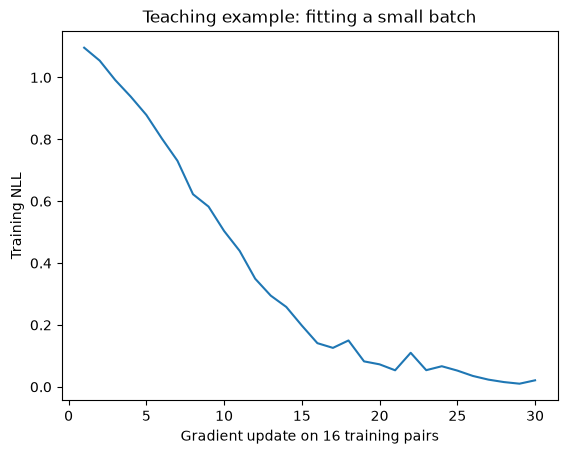

In [17]:
training_example_rows = folds.loc[folds.fold_seed_0 != 0].iloc[:16]
teaching = select_text(data, training_example_rows)
X_teaching = encoder.transform(teaching, "unigram_counts")
set_seed()
small_model = PairMLP(X_teaching.shape[1], [32], .1)
optimizer = torch.optim.AdamW(small_model.parameters(), lr=.01)
losses = []
for step in range(30):
    small_model.train()
    optimizer.zero_grad(set_to_none=True)
    logp = small_model(sparse_tensor(X_teaching))
    loss = nn.NLLLoss()(logp, torch.as_tensor(teaching.label.to_numpy(), dtype=torch.long))
    loss.backward()
    optimizer.step()
    losses.append(float(loss.item()))
plt.plot(np.arange(1, 31), losses)
plt.xlabel("Gradient update on 16 training pairs")
plt.ylabel("Training NLL")
plt.title("Teaching example: fitting a small batch")
plt.show()

### Save the tokenizer, feature mapping and model together

These compact functions also read the completed experiment's existing bundles.
Historical results keep their original provenance. Newly saved streamlined
models are marked separately; simplifying the code does not relabel old results.

In [18]:
def save_pipeline(directory, encoder, fitted, representation, input_mode="pair"):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=False)
    encoder.save(directory / "preprocessing")
    if fitted["kind"] == "logistic":
        joblib.dump(fitted["estimator"], directory / "model.joblib")
    elif fitted["kind"] == "class_prior":
        np.save(directory / "prior.npy", fitted["estimator"])
    else:
        torch.save(fitted["estimator"].state_dict(), directory / "model.pt")
    metadata = {key: fitted[key] for key in ("kind", "input_dim", "settings", "history", "fit_info")}
    metadata.update(model_version="streamlined-v1", representation=representation, input_mode=input_mode,
                    label_names=LABELS, class_order=[0, 1, 2],
                    source_notebook_code_sha256=notebook_code_hash())
    metadata["artifact_sha256"] = {str(p.relative_to(directory)): file_hash(p)
                                 for p in directory.rglob("*") if p.is_file()}
    (directory / "bundle.json").write_text(json.dumps(metadata, indent=2))


def load_pipeline(directory):
    directory = local_path(directory)
    metadata = read_json(directory / "bundle.json")
    assert metadata["model_version"] in ("v1", "streamlined-v1")
    assert metadata["label_names"] == LABELS and metadata["class_order"] == [0, 1, 2]
    check_files(directory, metadata["artifact_sha256"])
    encoder = PairEncoder.load(directory / "preprocessing")
    if metadata["kind"] == "logistic":
        estimator = joblib.load(directory / "model.joblib")
    elif metadata["kind"] == "class_prior":
        estimator = np.load(directory / "prior.npy", allow_pickle=False)
    else:
        settings = metadata["settings"]
        estimator = PairMLP(metadata["input_dim"], settings["hidden_dims"][metadata["kind"]], settings["dropout"])
        estimator.load_state_dict(torch.load(directory / "model.pt", weights_only=True, map_location="cpu"))
    return encoder, {**metadata, "estimator": estimator}


def predict_text(encoder, fitted, frame):
    matrix = encoder.transform(frame, fitted["representation"])
    if fitted["input_mode"] == "hypothesis_only":
        matrix = matrix[:, matrix.shape[1] // 2:]
    return predict_proba(fitted, matrix)

### From logits to a decision

Here is the complete calculation for the illustrative dog/sleep pair above,
using a saved unigram logistic model. Softmax gives a distribution over labels;
argmax turns that distribution into a decision. This invented pair has no gold
label and contributes no evaluation score.

In [19]:
example_checkpoint = cv_metrics.query("seed == 0 and fold == 0 and representation == 'unigram_counts' and classifier == 'logistic' and input_mode == 'pair'").iloc[0].checkpoint
example_encoder, example_model = load_pipeline(example_checkpoint)
example_input = example_encoder.transform(example_frame, "unigram_counts")
example_logits = (example_input @ example_model["estimator"].coef_.T + example_model["estimator"].intercept_)[0]
manual_probabilities = np.exp(example_logits - example_logits.max())
manual_probabilities /= manual_probabilities.sum()
assert np.allclose(manual_probabilities, predict_proba(example_model, example_input)[0])
display(pd.DataFrame({"label": LABELS, "logit": example_logits, "probability": manual_probabilities}))
print("Decision:", LABELS[manual_probabilities.argmax()])

,label,logit,probability
0,entailment,0.429110,0.467511
1,neutral,0.190782,0.368372
2,contradiction,-0.617733,0.164117


Decision: entailment


## 6. The short tokenizer/model search

Three joint recipes were tested per representation/model pair: baseline 5k BPE,
compact/lowercase 3k BPE with stronger regularization, and 8k BPE with a larger
learning rate. They also vary merge frequency, bigram inventory, C, dropout,
width and batch size. These are **joint pipeline changes**, so they do not isolate
an individual hyperparameter's effect.

The completed pass used 100,001 training rows, all 9,839 eligible validation
rows, seed 0, patience 3 and at most 8 neural epochs. It finished in **7m 58s**:
nine compatible observations were reused and 18 new models fitted. The original
reuse audit is preserved in the details notebook. Here, a new search uses one
clear loop, can resume its own completed trials, and has a 15-minute cap.

In [20]:
class BudgetExpired(TimeoutError):
    pass


@contextmanager
def time_budget(seconds=MAX_SECONDS):
    """Linux/Jupyter main-thread timer; completed trials survive an interruption."""
    if not 0 < seconds <= MAX_SECONDS:
        raise ValueError("Use a budget between 0 and 900 seconds.")
    def expired(signum, frame):
        raise BudgetExpired("The time allowance has elapsed.")
    previous = signal.getsignal(signal.SIGALRM)
    signal.signal(signal.SIGALRM, expired)
    old_timer = signal.setitimer(signal.ITIMER_REAL, seconds)
    started = perf_counter()
    try:
        yield
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, previous)
        if old_timer[0]:
            signal.setitimer(signal.ITIMER_REAL, max(.001, old_timer[0] - (perf_counter() - started)), old_timer[1])


def candidate_config(variant, base=BASE):
    config = deepcopy(base)
    for key in ("tokenizer", "bigram_features", "logistic_training", "neural_training"):
        config[key].update(deepcopy(variant.get(key, {})))
    return config


display(pd.DataFrame(SEARCH["candidates"]))

,name,tokenizer,bigram_features,logistic_training,neural_training
0,baseline,NaN,NaN,NaN,NaN
1,compact_regularized,"{'vocab_size': 3000, 'min_frequency': 2, 'norm...","{'max_features': 10000, 'min_frequency': 2}",{'C': 0.1},"{'learning_rate': 0.001, 'dropout': 0.3, 'weig..."
2,larger_faster_learning,"{'vocab_size': 8000, 'min_frequency': 5, 'norm...","{'max_features': 10000, 'min_frequency': 5}",{'C': 0.01},"{'learning_rate': 0.003, 'dropout': 0.1, 'weig..."


In [21]:
def run_search(training, validation, directory, *, policy=SEARCH, base=BASE):
    """A fresh or resumed small search; use development data only, never outer held-out/test."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    results = []
    specification = {"policy": policy, "base": base,
        "training_ids": training.example_id.tolist(), "validation_ids": validation.example_id.tolist(),
        "source_sha256": notebook_code_hash()}
    marker = directory / "plan.json"
    if marker.exists():
        assert read_json(marker) == specification, "Use a new directory for a changed experiment."
    else:
        marker.write_text(json.dumps(specification))
    try:
        with time_budget(policy["time_budget_seconds"]):
            for variant in policy["candidates"]:
                config = candidate_config(variant, base)
                fitted_encoder, train_tokens = None, None
                for representation in REPRESENTATIONS:
                    X_train, X_validation = None, None
                    for kind in CLASSIFIERS:
                        name = f"{variant['name']}__{representation}__{kind}"
                        trial = directory / name
                        if (trial / "result.json").exists():
                            result = read_json(trial / "result.json")
                            load_pipeline(trial / "bundle")  # Check model and preprocessing hashes too.
                            assert file_hash(trial / "probabilities.npz") == result["probabilities_sha256"]
                            with np.load(trial / "probabilities.npz", allow_pickle=False) as saved:
                                assert saved["example_id"].tolist() == validation.example_id.tolist()
                                assert np.array_equal(saved["label"], validation.label)
                                recomputed = score(saved["label"], saved["probabilities"])
                            assert all(np.isclose(result[m], recomputed[m], atol=1e-12, rtol=0) for m in recomputed)
                            results.append(result)
                            continue
                        if fitted_encoder is None:
                            fitted_encoder, train_tokens = PairEncoder.fit(training, config)
                            validation_tokens = encode_pairs(fitted_encoder.tokenizer, validation)
                        if X_train is None:
                            X_train = feature_matrix(fitted_encoder, train_tokens, representation)
                            X_validation = feature_matrix(fitted_encoder, validation_tokens, representation)
                        model = fit_model(X_train, training.label, kind, config,
                            validation=(X_validation, validation.label), epochs=policy["absolute_max_epochs"],
                            patience=policy["patience"], seed=0)
                        probabilities = predict_proba(model, X_validation)
                        temporary = directory / (name + ".working")
                        if temporary.exists():
                            import shutil
                            shutil.rmtree(temporary)
                        temporary.mkdir()
                        save_pipeline(temporary / "bundle", fitted_encoder, model, representation)
                        np.savez_compressed(temporary / "probabilities.npz", label=validation.label.to_numpy(),
                                            probabilities=probabilities, example_id=validation.example_id.to_numpy(dtype=str))
                        result = {"variant": variant["name"], "representation": representation, "classifier": kind,
                                  **score(validation.label, probabilities), "history": model["history"],
                                  "fit_info": model["fit_info"], "eligible": model["fit_info"].get("converged", True),
                                  "probabilities_sha256": file_hash(temporary / "probabilities.npz")}
                        (temporary / "result.json").write_text(json.dumps(result))
                        temporary.rename(trial)
                        results.append(result)
                        print(name, f"validation accuracy={result['accuracy']:.4f}", flush=True)
    except BudgetExpired:
        print("Budget reached; report completed trials only. An explicit resume gets another allowance.")
    return pd.DataFrame(results)


RUN_SEARCH = False
if RUN_SEARCH:
    search_results_new = run_search(select_text(data, search_rows),
        select_text(data, eligible_validation, "validation"), NEW_RUNS / "search")

### Read and independently check the completed search

Each saved trial contains its validation probabilities. We recompute its metrics
and verify row order, labels and file hashes. This reads existing results and
does not train a model or touch test predictions.

In [22]:
def read_completed_search():
    pointer = read_json(OUTPUT / "tuning/latest.json")
    directory = local_path(pointer["run_dir"])
    manifest = read_json(directory / "manifest.json")
    assert manifest["status"] == "complete" and manifest["specification"]["policy"] == SEARCH
    saved_rows = pd.read_parquet(directory / "screening_rows.parquet")
    for column in ("clean_index", "example_id", "premise_group", "label"):
        assert np.array_equal(saved_rows[column], search_rows[column])
    validation = select_text(data, eligible_validation, "validation")
    plan = read_json(directory / "plan.json")
    imported = read_json(directory / "reused_trials.json")
    paths = []
    for item in imported:
        path = local_path(item["directory"])
        assert file_hash(path / "trial.json") == item["trial_sha256"]
        paths.append(path)
    paths += [p.parent for p in directory.glob("budgeted/trials/*/trial.json")
              if not p.parent.name.endswith(".working")]
    recipes = {candidate["candidate_id"]: candidate for candidate in plan}
    records = []
    for path in paths:
        row = read_json(path / "trial.json")
        check_files(path, row["artifact_sha256"])
        with np.load(path / "validation_predictions.npz", allow_pickle=False) as saved:
            assert saved["example_id"].tolist() == validation.example_id.tolist()
            assert np.array_equal(saved["label"], validation.label)
            metrics = score(saved["label"], saved["probabilities"])
        assert all(np.isclose(row[m], metrics[m], atol=1e-12, rtol=0) for m in metrics)
        records.append({**row, "variant": recipes[row["candidate_id"]]["origin"]})
    assert len(records) == len(recipes) == manifest["completed_trials"] == 27
    assert len({r["candidate_id"] for r in records}) == 27
    return manifest, pd.DataFrame(records)


search_manifest, search_results = read_completed_search()
search_best = search_results.loc[search_results.eligible].sort_values(
    ["accuracy", "nll", "candidate_id"], ascending=[False, True, True]).groupby(
    ["representation", "classifier"], sort=False).head(1)
display(search_best[["representation", "classifier", "variant", "accuracy", "nll", "best_epoch", "needs_ceiling_review"]])
print("Completed observations:", len(search_results), "| reused:", search_manifest["reused_trials"],
      "| new fits:", search_manifest["new_trials_this_invocation"],
      "| minutes:", round(search_manifest["elapsed_seconds_this_invocation"] / 60, 2))

,representation,classifier,variant,accuracy,nll,best_epoch,needs_ceiling_review
22,unigram_counts,mlp_one_hidden,larger_faster_learning,0.678321,0.862387,4.0,False
5,indicators,mlp_two_hidden,baseline,0.676593,0.867091,4.0,False
0,indicators,mlp_one_hidden,baseline,0.674967,0.835071,5.0,False
12,unigram_counts,mlp_two_hidden,compact_regularized,0.673239,0.877533,7.0,True
6,indicators,logistic,baseline,0.635329,0.844323,NaN,False
1,unigram_counts,logistic,baseline,0.635227,0.854906,NaN,False
21,bigram_counts,mlp_two_hidden,compact_regularized,0.611038,0.991751,5.0,False
16,bigram_counts,mlp_one_hidden,compact_regularized,0.606871,0.863701,2.0,False
13,bigram_counts,logistic,compact_regularized,0.599350,0.870934,NaN,False


Completed observations: 27 | reused: 9 | new fits: 18 | minutes: 7.97


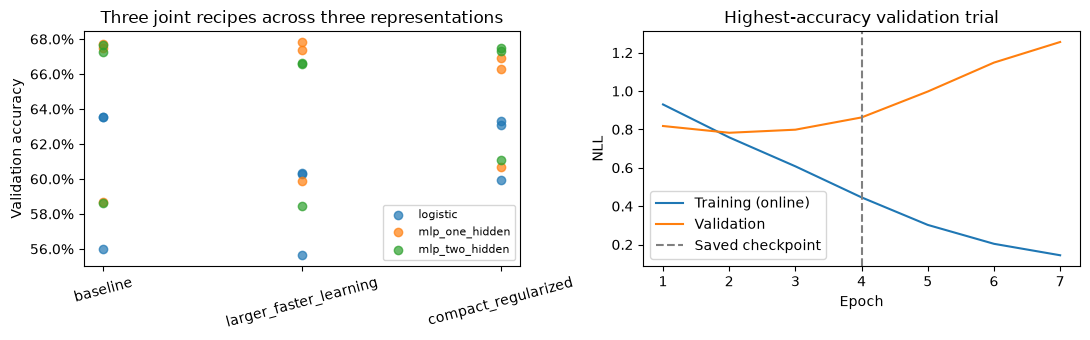

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for kind in CLASSIFIERS:
    subset = search_results.query("classifier == @kind")
    axes[0].scatter(subset.variant, subset.accuracy, label=kind, alpha=.7)
axes[0].set(ylabel="Validation accuracy", title="Three joint recipes across three representations")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].tick_params(axis="x", labelrotation=15)
axes[0].legend(fontsize=8)
best_trial = search_results.sort_values(["accuracy", "nll"], ascending=[False, True]).iloc[0]
curves = pd.DataFrame(best_trial.history)
axes[1].plot(curves.epoch, curves.train_nll_online, label="Training (online)")
axes[1].plot(curves.epoch, curves.validation_nll, label="Validation")
axes[1].axvline(best_trial.best_epoch, color="gray", linestyle="--", label="Saved checkpoint")
axes[1].set(xlabel="Epoch", ylabel="NLL", title="Highest-accuracy validation trial")
axes[1].legend()
plt.tight_layout()
plt.show()

The highest validation accuracy is **67.83%**, from unigram MLP1 with the larger
recipe, versus **67.74%** for its baseline-hyperparameter counterpart. The gain
is only **0.09 percentage points**, and NLL worsens (0.8624 versus 0.8344).
This does not establish a robust generalization improvement. Compact bigram
systems improve more on this validation set, but several settings changed jointly.
The curve also shows overfitting in NLL: validation NLL rises while training
NLL falls. Selecting epoch 4 by accuracy does not minimise validation NLL.

The selected compact unigram MLP2 has a ceiling-review flag: training stopped at
8 epochs before patience expired. Treat its result as budget-limited. This search
uses one seed and a subset, with no full-data confirmation. Its validation scores
must not be compared directly with the differently sized baseline CV scores.

## 7. Cross-validation comparison

The implementation below shows the complete evaluation loop. Each fold fits its
own preprocessing, then the nine primary systems, the training-prior baseline
and a hypothesis-only unigram logistic diagnostic. CV uses the frozen three-epoch
schedule and never passes its outer held-out data into checkpoint selection.

`RUN_CV` stays false. The existing baseline took 21.62 minutes; a new streamlined
invocation stops at 15 minutes and may return an incomplete grid. Only a complete,
paired grid is suitable for the comparisons below. Detailed historical resumption
and budget machinery is retained in the details notebook.

In [24]:
def run_cv(data, assignments, directory, *, config=BASE, seeds=(0, 3, 5), n_splits=5,
           max_seconds=MAX_SECONDS):
    """Fixed-recipe CV. Save each completed score/prediction; do not tune on outer folds."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=False)
    rows = []
    try:
        with time_budget(max_seconds):
            for repetition, seed in enumerate(seeds):
                for fold in range(n_splits):
                    heldout = assignments[f"fold_seed_{seed}"].eq(fold)
                    train_rows, heldout_rows = assignments.loc[~heldout], assignments.loc[heldout]
                    assert set(train_rows.premise_group).isdisjoint(heldout_rows.premise_group)
                    training, evaluation = select_text(data, train_rows), select_text(data, heldout_rows)
                    fitted_encoder, tokens = PairEncoder.fit(training, config)
                    heldout_tokens = encode_pairs(fitted_encoder.tokenizer, evaluation)
                    for representation in REPRESENTATIONS:
                        X = feature_matrix(fitted_encoder, tokens, representation)
                        Z = feature_matrix(fitted_encoder, heldout_tokens, representation)
                        systems = [(kind, "pair") for kind in CLASSIFIERS]
                        if representation == "unigram_counts":
                            systems += [("class_prior", "pair"), ("logistic", "hypothesis_only")]
                        for kind, mode in systems:
                            x, z = (X, Z) if mode == "pair" else (X[:, X.shape[1] // 2:], Z[:, Z.shape[1] // 2:])
                            fitted = fit_model(x, training.label, kind, config, seed=config["seeds"]["model"])
                            probabilities = predict_proba(fitted, z)
                            system_id = f"{representation}__{kind}__{mode}"
                            name = f"seed{seed}_fold{fold}_{system_id}"
                            predictions = heldout_rows.reset_index(drop=True).copy()
                            predictions["prediction"] = probabilities.argmax(1)
                            predictions[PROBABILITY_COLUMNS] = probabilities
                            predictions.to_parquet(directory / f"{name}.parquet", index=False)
                            save_pipeline(directory / name, fitted_encoder, fitted, representation, mode)
                            rows.append({"system_id": system_id, "representation": representation,
                                "classifier": kind, "input_mode": mode, "primary": kind in CLASSIFIERS and mode == "pair",
                                "repetition": repetition, "seed": seed, "fold": fold,
                                "training_rows": len(training), "heldout_rows": len(evaluation),
                                "converged": fitted["fit_info"].get("converged", True), **score(evaluation.label, probabilities)})
                            pd.DataFrame(rows).to_csv(directory / "fold_metrics.csv", index=False)
    except BudgetExpired:
        print("CV budget reached. Partial scores are not a complete paired comparison.")
    complete = len(rows) == len(seeds) * n_splits * 11
    (directory / "status.json").write_text(json.dumps({"complete": complete, "units": len(rows), "test_scored": False}))
    return pd.DataFrame(rows)


RUN_CV = False
if RUN_CV:
    cv_scores_new = run_cv(data, folds, NEW_RUNS / "cv")

### Verify the completed baseline against predictions

We check all **165 fits**, recomputing accuracy/NLL/F1 from their saved
probabilities and checking row IDs, gold labels and fold pairing. These are
checks on completed work, not new training. Mean scores weight folds equally.
Fold SD is descriptive; overlapping training sets make the scores dependent.

In [25]:
def audit_cv(metrics, assignments):
    assert len(metrics) == 165 and not metrics.duplicated(KEYS + ["system_id"]).any()
    assert metrics.groupby("system_id").size().eq(15).all()
    assert metrics.groupby(KEYS).size().eq(11).all()
    for column in ("feature_id", "training_rows", "heldout_rows"):
        assert metrics.groupby(KEYS)[column].nunique().eq(1).all()
    gold = np.asarray(data["train"]["label"])
    for row in metrics.itertuples():
        predictions = pd.read_parquet(local_path(row.predictions))
        expected = assignments.loc[assignments[f"fold_seed_{row.seed}"].eq(row.fold)]
        assert predictions.example_id.tolist() == expected.example_id.tolist()
        assert np.array_equal(predictions.label, expected.label)
        assert np.array_equal(gold[expected.clean_index], predictions.label)
        p = predictions[PROBABILITY_COLUMNS].to_numpy()
        assert np.array_equal(predictions.prediction, p.argmax(1))
        computed = score(predictions.label, p)
        assert all(np.isclose(getattr(row, name), value, atol=1e-12, rtol=0) for name, value in computed.items())
        complete = read_json(local_path(row.predictions).parent.parent / "complete.json")
        check_files(local_path(row.predictions).parent, complete["artifact_sha256"])
    assert metrics.query("classifier == 'logistic'").converged.eq(True).all()
    print("Checked all 165 fits: gold/row order, probabilities, metrics, artifacts and shared partitions.")


audit_cv(cv_metrics, folds)
cv_summary = cv_metrics.groupby(["system_id", "representation", "classifier", "input_mode", "primary"], sort=False).agg(
    mean_accuracy=("accuracy", "mean"), sd_accuracy=("accuracy", "std"), mean_nll=("nll", "mean"),
    mean_macro_f1=("macro_f1", "mean")).reset_index()
display(cv_summary.sort_values("mean_accuracy", ascending=False).round(4))

Checked all 165 fits: gold/row order, probabilities, metrics, artifacts and shared partitions.


,system_id,representation,classifier,input_mode,primary,mean_accuracy,sd_accuracy,mean_nll,mean_macro_f1
5,indicators__mlp_two_hidden__pair,indicators,mlp_two_hidden,pair,True,0.6275,0.0045,0.8514,0.6261
10,unigram_counts__mlp_two_hidden__pair,unigram_counts,mlp_two_hidden,pair,True,0.6272,0.0033,0.8503,0.6257
9,unigram_counts__mlp_one_hidden__pair,unigram_counts,mlp_one_hidden,pair,True,0.6245,0.0039,0.8466,0.6235
4,indicators__mlp_one_hidden__pair,indicators,mlp_one_hidden,pair,True,0.6235,0.0036,0.8470,0.6225
7,unigram_counts__logistic__hypothesis_only,unigram_counts,logistic,hypothesis_only,False,0.6102,0.0033,0.8890,0.6095
8,unigram_counts__logistic__pair,unigram_counts,logistic,pair,True,0.6076,0.0027,0.9213,0.6069
3,indicators__logistic__pair,indicators,logistic,pair,True,0.6075,0.0024,0.9199,0.6069
1,bigram_counts__mlp_one_hidden__pair,bigram_counts,mlp_one_hidden,pair,True,0.5532,0.0041,0.9311,0.5522
2,bigram_counts__mlp_two_hidden__pair,bigram_counts,mlp_two_hidden,pair,True,0.5508,0.0044,0.9401,0.5486
0,bigram_counts__logistic__pair,bigram_counts,logistic,pair,True,0.5375,0.0041,0.9833,0.5370


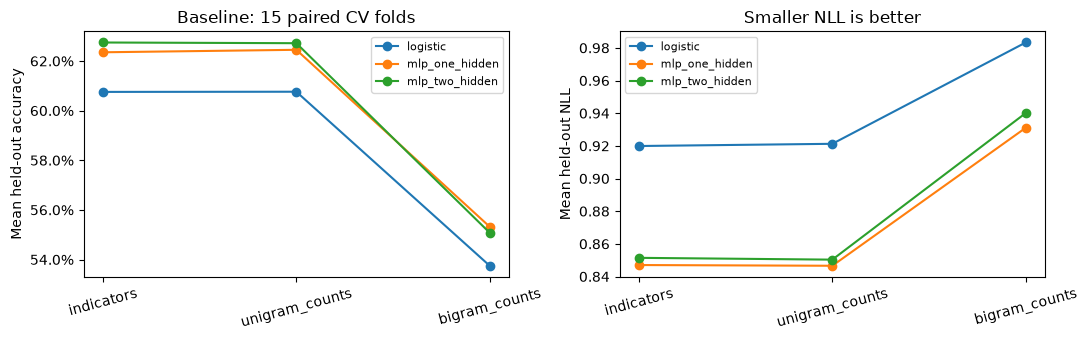

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
primary = cv_summary.loc[cv_summary.primary]
for kind in CLASSIFIERS:
    rows = primary.loc[primary.classifier.eq(kind)].set_index("representation").loc[REPRESENTATIONS]
    axes[0].plot(REPRESENTATIONS, rows.mean_accuracy, marker="o", label=kind)
    axes[1].plot(REPRESENTATIONS, rows.mean_nll, marker="o", label=kind)
axes[0].set(ylabel="Mean held-out accuracy", title="Baseline: 15 paired CV folds")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(ylabel="Mean held-out NLL", title="Smaller NLL is better")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=15)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The highest mean baseline accuracy is **62.75%** (indicator MLP2). The lowest mean
NLL is **0.8466** (unigram MLP1). Indicators and counts are close; pure bigrams are
weaker under this fixed inventory. The hypothesis-only logistic diagnostic scores
**61.02%**, close to **60.76%** for pair-input unigram logistic. This suggests
checking label cues and the model's limited interactions; it does not prove that
premises are unnecessary for NLI.

### Check a saved model from raw text

The following reloads one fold-0 bundle per system, including both diagnostics,
and checks raw-text probabilities against the saved held-out predictions.

In [27]:
reload_differences = []
for row in cv_metrics.query("seed == 0 and fold == 0").itertuples():
    saved = pd.read_parquet(local_path(row.predictions)).iloc[:32]
    frame = select_text(data, saved)
    saved_encoder, saved_model = load_pipeline(row.checkpoint)
    replay = predict_text(saved_encoder, saved_model, frame)
    difference = float(np.max(np.abs(replay - saved[PROBABILITY_COLUMNS].to_numpy())))
    assert difference < 1e-6
    reload_differences.append({"system": row.system_id, "max_probability_difference": difference})
display(pd.DataFrame(reload_differences))

,system,max_probability_difference
0,bigram_counts__logistic__pair,2.172911e-08
1,bigram_counts__mlp_one_hidden__pair,0.000000e+00
2,bigram_counts__mlp_two_hidden__pair,0.000000e+00
3,indicators__logistic__pair,2.491449e-08
4,indicators__mlp_one_hidden__pair,0.000000e+00
5,indicators__mlp_two_hidden__pair,0.000000e+00
6,unigram_counts__class_prior__pair,0.000000e+00
7,unigram_counts__logistic__hypothesis_only,2.118065e-08
8,unigram_counts__logistic__pair,2.671708e-08
9,unigram_counts__mlp_one_hidden__pair,0.000000e+00


## 8. Bayesian comparison and ROPE

We compare matched fold scores with a Bayesian correlated-t posterior. Differences
are **B − A**, so positive values favour B. Our preselected ROPE is **±0.005
accuracy (±0.5 percentage points)**: a project judgement about practical value,
not a sampling-error margin. Sensitivity checks use ±0.25 and ±1 pp.

For `n=15` scores, `runs=3` and `k=5` folds per run, the posterior has mean
`mean(B−A)`, `df=14` and Student scale `sd(B−A) × sqrt(1/15 + 1/4)`. The correction
accounts approximately for dependence from overlapping training sets. Its scale
squared is 4.75 times the naive independent-score value. Student scale is not
posterior SD; the latter multiplies it by `sqrt(14/12)`.

In [28]:
def correlated_posterior(a, b, runs=3, rope=.005):
    a, b = np.asarray(a, float), np.asarray(b, float)
    assert a.ndim == 1 and a.shape == b.shape and len(a) >= 4
    assert len(a) % runs == 0 and len(a) // runs >= 2 and rope > 0
    assert np.isfinite(a).all() and np.isfinite(b).all()
    assert ((0 <= a) & (a <= 1) & (0 <= b) & (b <= 1)).all()
    difference = b - a
    n, k = len(a), len(a) // runs
    mean, df = float(difference.mean()), n - 1
    scale = float(np.sqrt(difference.var(ddof=1) * (1/n + 1/(k-1))))
    if scale == 0:
        pa, pb = float(mean < -rope), float(mean > rope)
        pe, low, high = 1-pa-pb, mean, mean
    else:
        posterior = t(df, loc=mean, scale=scale)
        pa, pb = float(posterior.cdf(-rope)), float(posterior.sf(rope))
        pe = float(posterior.cdf(rope) - posterior.cdf(-rope))
        low, high = posterior.interval(.95)
    return {"mean_difference": mean, "student_scale": scale, "posterior_std": scale*np.sqrt(df/(df-2)),
            "ci_low": float(low), "ci_high": float(high), "p_a_better": pa, "p_equivalent": pe, "p_b_better": pb}


def compare_systems(metrics, contrasts, runs=3, rope=.005):
    assert not metrics.duplicated(KEYS + ["system_id"]).any()
    paired = metrics.pivot(index=KEYS, columns="system_id", values="accuracy").sort_index()
    assert not paired.isna().any().any()
    rows = []
    for contrast in contrasts.to_dict("records"):
        result = correlated_posterior(paired[contrast["system_a"]], paired[contrast["system_b"]], runs, rope)
        rows.append({**contrast, **result})
    return pd.DataFrame(rows)

In [29]:
analysis_pointer = read_json(OUTPUT / "manifests/bayesian_analysis.json")
analysis_directory = local_path(analysis_pointer["manifest_path"]).parent
analysis_manifest = read_json(analysis_directory / "manifest.json")
check_files(analysis_directory, analysis_manifest["artifact_sha256"])
assert analysis_manifest["specification"]["source_run_id"] == cv_manifest["run_id"]
assert analysis_manifest["specification"]["source_cv_manifest_sha256"] == file_hash(cv_directory / "manifest.json")
contrasts = pd.read_csv(analysis_directory / "contrasts.csv")
posteriors = compare_systems(cv_metrics, contrasts)
saved_posteriors = pd.read_csv(analysis_directory / "posteriors.csv")
fields = list(correlated_posterior(np.linspace(.5, .7, 15), np.linspace(.51, .72, 15)))
assert np.allclose(posteriors[fields], saved_posteriors[fields], atol=1e-12, rtol=0)
display(posteriors.loc[posteriors.primary, ["label", "mean_difference", "p_a_better", "p_equivalent", "p_b_better"]].round(6))
print("Independently recomputed all 28 saved contrasts.")

,label,mean_difference,p_a_better,p_equivalent,p_b_better
0,LR: Indicators → Unigrams,0.000072,0.000001,0.999998,0.000001
1,LR: Indicators → Bigrams,-0.070061,1.000000,0.000000,0.000000
2,LR: Unigrams → Bigrams,-0.070133,1.000000,0.000000,0.000000
3,MLP1: Indicators → Unigrams,0.001000,0.000000,0.999960,0.000040
4,MLP1: Indicators → Bigrams,-0.070300,1.000000,0.000000,0.000000
5,MLP1: Unigrams → Bigrams,-0.071300,1.000000,0.000000,0.000000
6,MLP2: Indicators → Unigrams,-0.000283,0.004293,0.993637,0.002070
7,MLP2: Indicators → Bigrams,-0.076682,1.000000,0.000000,0.000000
8,MLP2: Unigrams → Bigrams,-0.076399,1.000000,0.000000,0.000000
9,Indicators: LR → MLP1,0.015965,0.000000,0.000003,0.999997


Independently recomputed all 28 saved contrasts.


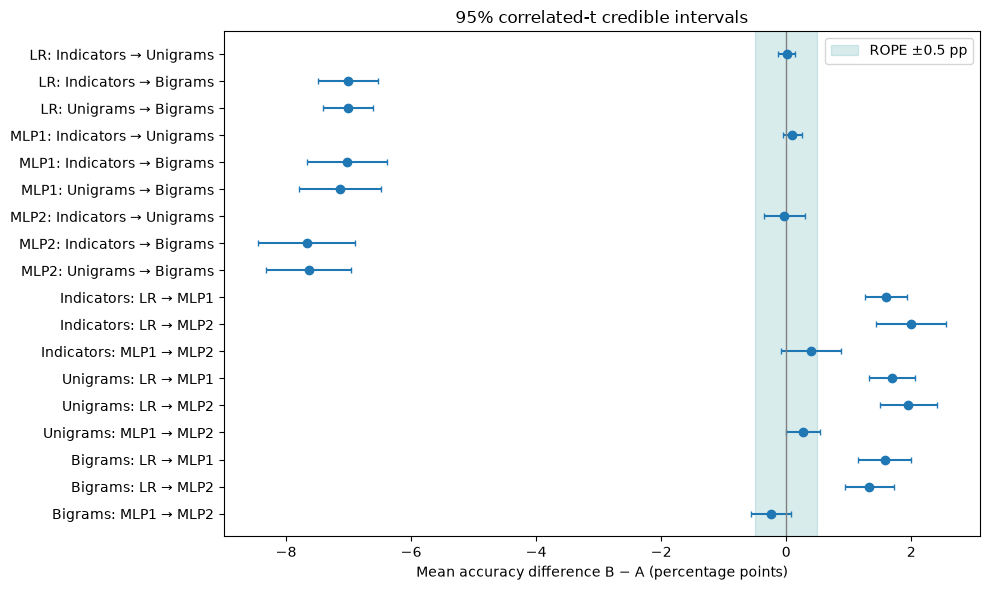

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
rows = posteriors.loc[posteriors.primary].iloc[::-1]
ax.axvspan(-.5, .5, color="teal", alpha=.15, label="ROPE ±0.5 pp")
means = rows.mean_difference.to_numpy() * 100
errors = np.vstack((means - rows.ci_low.to_numpy()*100, rows.ci_high.to_numpy()*100 - means))
ax.errorbar(means, np.arange(len(rows)), xerr=errors, fmt="o", capsize=2)
ax.set_yticks(np.arange(len(rows)), rows.label)
ax.axvline(0, color="gray", linewidth=1)
ax.set(xlabel="Mean accuracy difference B − A (percentage points)", title="95% correlated-t credible intervals")
ax.legend()
plt.tight_layout()
plt.show()

Under the baseline recipes, indicators and unigram counts have high posterior
probability of practical equivalence. Pure bigrams lose roughly 7–8 pp. MLPs
improve on logistic, while the benefit of another hidden layer is less decisive.
For unigram MLP2−MLP1 the mean is **+0.266 pp**, with **95.97%** probability inside
the ROPE. Hypothesis-only minus pair-input unigram logistic is **+0.258 pp**, with
**97.72%** probability inside it. These are conditional pairwise results, not a
probability of being globally best.

The correlated-normal/common-correlation assumptions are approximations: fold
sizes differ slightly, accuracy is bounded, and all runs use one dataset/subset.
The split seeds are not independent model-initialization replications.

### ROPE sensitivity

How much does the practical-equivalence conclusion depend on our tolerance?
The table reports **posterior probability inside the ROPE (%)** for every primary
comparison at ±0.25, ±0.5 and ±1 percentage point. The underlying fold scores and
posterior stay fixed; only the region treated as practically equivalent changes.

For unigram MLP1 → MLP2 these probabilities are **44.89%, 95.97% and 100.00%**
(the last is rounded). Thus “practically equivalent” depends on the tolerance;
it is much less certain at ±0.25 pp. Indicators versus unigrams remain relatively
close, while the large pure-bigram deficits persist across these widths. Our
preselected **primary ROPE remains ±0.5 pp**; sensitivity does not select a new one.


In [31]:
saved_sensitivity = pd.read_csv(analysis_directory / "rope_sensitivity.csv")
sensitivity_rows = []
for rope in (.0025, .005, .01):
    recomputed = compare_systems(cv_metrics, contrasts, rope=rope)
    reference = saved_sensitivity.loc[np.isclose(saved_sensitivity.rope_half_width, rope)]
    assert np.allclose(recomputed[fields], reference[fields], atol=1e-12, rtol=0)
    sensitivity_rows.append(recomputed.assign(rope_half_width=rope))
rope_sensitivity = pd.concat(sensitivity_rows, ignore_index=True)
equivalence = rope_sensitivity.loc[rope_sensitivity.primary].pivot(
    index="label", columns="rope_half_width", values="p_equivalent")
equivalence = equivalence.reindex(contrasts.loc[contrasts.primary, "label"])
display((100 * equivalence).rename(columns=lambda width: f"ROPE ±{width * 100:g} pp").round(2))
print("Probability inside the ROPE (%). Checked all 84 sensitivity rows; primary ROPE: ±0.5 pp.")

rope_half_width,ROPE ±0.25 pp,ROPE ±0.5 pp,ROPE ±1 pp
label,,,
LR: Indicators → Unigrams,99.85,100.00,100.00
LR: Indicators → Bigrams,0.00,0.00,0.00
LR: Unigrams → Bigrams,0.00,0.00,0.00
MLP1: Indicators → Unigrams,97.05,100.00,100.00
MLP1: Indicators → Bigrams,0.00,0.00,0.00
MLP1: Unigrams → Bigrams,0.00,0.00,0.00
MLP2: Indicators → Unigrams,86.68,99.36,100.00
MLP2: Indicators → Bigrams,0.00,0.00,0.00
MLP2: Unigrams → Bigrams,0.00,0.00,0.00


Probability inside the ROPE (%). Checked all 84 sensitivity rows; primary ROPE: ±0.5 pp.


## 9. Held-out errors and final design

Use **split seed 0 only**, fixed before reviewing cases: each of the 60,005 CV
rows has one held-out prediction per system. This avoids counting the three
repetitions as independent errors. The models here are the historical **three-epoch
baseline**, not the later validation-selected fits. These pooled descriptive scores
will differ slightly from the 15-fold means in section 7.

Our reference model (the **anchor**) is unigram MLP1. We compare all systems,
then examine class confusions, simple text slices and shared failures. These
are diagnostics, not new CV estimates or evidence of an error's internal cause.


In [32]:
def collect_oof(metrics, assignments, seed=0):
    """One held-out prediction per row/system, using one preselected CV repetition."""
    rows = assignments.reset_index(drop=True).copy()
    assert rows.example_id.is_unique
    probabilities, scores = {}, []
    for system, units in metrics.loc[metrics.seed.eq(seed)].groupby("system_id", sort=True):
        saved = pd.concat([pd.read_parquet(local_path(path)) for path in units.predictions], ignore_index=True)
        assert saved.example_id.is_unique and len(saved) == len(rows)
        saved = saved.set_index("example_id").loc[rows.example_id].reset_index()
        for column in ("clean_index", "label", "premise_group"):
            assert np.array_equal(saved[column], rows[column]), f"Misaligned {system}: {column}"
        assert np.array_equal(saved.fold, rows[f"fold_seed_{seed}"])
        p = validate_probabilities(saved[PROBABILITY_COLUMNS].to_numpy(), len(rows))
        assert np.array_equal(saved.prediction, p.argmax(1))
        rows[system] = saved.prediction.to_numpy(dtype=np.int8)
        probabilities[system] = p
        scores.append({"system": system, **score(rows.label, p)})
    assert probabilities
    return rows, probabilities, pd.DataFrame(scores)


def text_diagnostics(frame):
    """Surface cues for descriptive slices; these do not identify causes of errors."""
    words = lambda text: set(re.findall(r"[a-z]+(?:['’][a-z]+)?", text.lower()))
    overlap = [len(words(p) & words(h)) / max(1, len(words(h)))
               for p, h in zip(frame.premise, frame.hypothesis)]
    negation = r"\b(?:no|not|never|nobody|nothing|neither|nor|without)\b|n['’]t\b"
    return pd.DataFrame({"hypothesis_overlap": overlap,
        "negation_cue": (frame.premise + " " + frame.hypothesis).str.contains(negation, case=False, regex=True)},
        index=frame.index)


def slice_scores(rows, systems):
    masks = {"All rows": np.ones(len(rows), bool), "Negation cue": rows.negation_cue,
             "No negation cue": ~rows.negation_cue, "High overlap (≥.8)": rows.hypothesis_overlap.ge(.8),
             "High overlap, non-entailment": rows.hypothesis_overlap.ge(.8) & rows.label.ne(0),
             "Low overlap (≤.2)": rows.hypothesis_overlap.le(.2)}
    results = []
    for name, mask in masks.items():
        subset = rows.loc[mask]
        if len(subset):
            results.append({"slice": name, "rows": len(subset), "gold_entailment": subset.label.eq(0).mean(),
                **{label: subset[system].eq(subset.label).mean() for label, system in systems.items()}})
    return pd.DataFrame(results)


def shared_errors(rows, anchor, systems):
    wrong = rows[anchor].ne(rows.label)
    result = []
    for label, system in systems.items():
        other = rows[system].ne(rows.label)
        result.append({"comparator": label, "both_correct": int((~wrong & ~other).sum()),
            "both_wrong": int((wrong & other).sum()), "anchor_wrong_only": int((wrong & ~other).sum()),
            "comparator_wrong_only": int((~wrong & other).sum()),
            "same_wrong_label": int((wrong & other & rows[anchor].eq(rows[system])).sum())})
    return pd.DataFrame(result)


def choose_error_cases(rows, anchor, bigram, hypothesis, neural_comparators, seed=19):
    """Fifty purposively sampled cases; unique example AND premise, not a prevalence sample."""
    shuffled = rows.sample(frac=1, random_state=seed)
    chosen, groups = [], set()
    def take(pool, count, reason):
        available = pool.loc[~pool.premise_group.isin(groups)].drop_duplicates("premise_group").head(count).copy()
        assert len(available) == count, f"Not enough cases for {reason}"
        groups.update(available.premise_group)
        available["selection_reason"] = reason
        chosen.append(available)
    for gold in range(3):
        for predicted in range(3):
            if gold != predicted:
                take(shuffled.loc[shuffled.label.eq(gold) & shuffled[anchor].eq(predicted)], 5,
                     f"Anchor confusion {LABELS[gold]} → {LABELS[predicted]}")
    wrong = shuffled[anchor].ne(shuffled.label)
    shared = wrong.copy()
    for system in neural_comparators:
        shared &= shuffled[system].ne(shuffled.label)
    take(shuffled.loc[shared].sort_values("anchor_confidence", ascending=False), 5, "Confident shared neural error")
    take(shuffled.loc[wrong & shuffled[bigram].eq(shuffled.label)], 5, "Bigram correct, anchor wrong")
    take(shuffled.loc[wrong & shuffled[hypothesis].eq(shuffled.label)], 5, "Hypothesis-only correct, anchor wrong")
    take(shuffled.loc[~wrong & shuffled[bigram].ne(shuffled.label)], 5, "Anchor correct, bigram wrong")
    result = pd.concat(chosen, ignore_index=True)
    assert len(result) == 50 and result.example_id.is_unique and result.premise_group.is_unique
    return result


In [33]:
anchor = "unigram_counts__mlp_one_hidden__pair"
bigram = "bigram_counts__mlp_one_hidden__pair"
hypothesis_only = "unigram_counts__logistic__hypothesis_only"
comparators = {"Unigram MLP2": "unigram_counts__mlp_two_hidden__pair",
    "Indicator MLP2": "indicators__mlp_two_hidden__pair", "Bigram MLP1": bigram,
    "Pair logistic": "unigram_counts__logistic__pair", "H-only logistic": hypothesis_only}
oof, oof_probabilities, oof_scores = collect_oof(cv_metrics, folds, seed=0)
oof_text = select_text(data, oof)
for column in ("premise", "hypothesis"):
    oof[column] = oof_text[column]
oof = pd.concat([oof, text_diagnostics(oof)], axis=1)
oof["anchor_confidence"] = oof_probabilities[anchor].max(1)
display(oof_scores.sort_values("accuracy", ascending=False).round(4))

error_directory = OUTPUT / "error_analysis" / cv_manifest["run_id"] / "split_seed_0"
error_directory.mkdir(parents=True, exist_ok=True)

,system,accuracy,nll,macro_f1
5,indicators__mlp_two_hidden__pair,0.6295,0.8501,0.6288
10,unigram_counts__mlp_two_hidden__pair,0.6278,0.8499,0.6269
9,unigram_counts__mlp_one_hidden__pair,0.6254,0.8461,0.6248
4,indicators__mlp_one_hidden__pair,0.6245,0.8475,0.6239
7,unigram_counts__logistic__hypothesis_only,0.6108,0.8897,0.6101
8,unigram_counts__logistic__pair,0.6076,0.9211,0.6070
3,indicators__logistic__pair,0.6075,0.9190,0.6069
1,bigram_counts__mlp_one_hidden__pair,0.5547,0.9301,0.5540
2,bigram_counts__mlp_two_hidden__pair,0.5522,0.9389,0.5506
0,bigram_counts__logistic__pair,0.5393,0.9823,0.5387


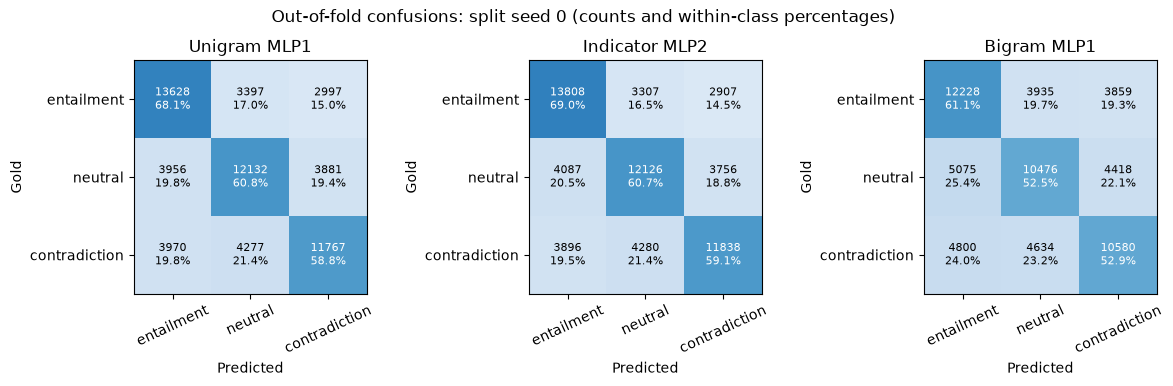

,system,class,precision,recall,f1-score,support
0,Unigram MLP1,entailment,0.6323,0.6807,0.6556,20022.0
1,Unigram MLP1,neutral,0.6125,0.6075,0.6100,19969.0
2,Unigram MLP1,contradiction,0.6311,0.5879,0.6088,20014.0
3,Indicator MLP2,entailment,0.6337,0.6896,0.6605,20022.0
4,Indicator MLP2,neutral,0.6151,0.6072,0.6112,19969.0
5,Indicator MLP2,contradiction,0.6399,0.5915,0.6147,20014.0
6,Bigram MLP1,entailment,0.5532,0.6107,0.5806,20022.0
7,Bigram MLP1,neutral,0.5501,0.5246,0.5370,19969.0
8,Bigram MLP1,contradiction,0.5611,0.5286,0.5444,20014.0


In [34]:
class_rows, confusion_rows = [], []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, system) in zip(axes, {"Unigram MLP1": anchor,
        "Indicator MLP2": comparators["Indicator MLP2"], "Bigram MLP1": bigram}.items()):
    counts = confusion_matrix(oof.label, oof[system], labels=[0, 1, 2])
    fractions = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(fractions, vmin=0, vmax=1, cmap="Blues")
    for gold in range(3):
        for predicted in range(3):
            ax.text(predicted, gold, f"{counts[gold, predicted]}\n{fractions[gold, predicted]:.1%}",
                    ha="center", va="center", fontsize=8, color="white" if fractions[gold, predicted] > .5 else "black")
            confusion_rows.append({"system": system, "gold": LABELS[gold], "predicted": LABELS[predicted],
                                   "count": int(counts[gold, predicted]), "row_fraction": fractions[gold, predicted]})
    ax.set(xticks=range(3), xticklabels=LABELS, yticks=range(3), yticklabels=LABELS,
           xlabel="Predicted", ylabel="Gold", title=name)
    ax.tick_params(axis="x", labelrotation=25)
    report = classification_report(oof.label, oof[system], labels=[0, 1, 2], target_names=LABELS,
                                   zero_division=0, output_dict=True)
    class_rows.extend({"system": name, "class": label, **report[label]} for label in LABELS)
fig.suptitle("Out-of-fold confusions: split seed 0 (counts and within-class percentages)")
plt.tight_layout()
fig.savefig(error_directory / "confusions.png", dpi=160, bbox_inches="tight")
plt.show()
class_scores = pd.DataFrame(class_rows)
display(class_scores.round(4))


The reference model's recall is **68.07% for entailment**, **60.75% for neutral**
and **58.79% for contradiction** in this repetition. Its largest off-diagonal
count is **4,277 contradiction → neutral** errors. Read each row as a fixed gold
class: percentages sum to one across its three predicted labels.

### Surface cues and shared failures

Overlap is the fraction of distinct, lowercased hypothesis words also present in
the premise, using the simple regex shown in `text_diagnostics`. Negation is a
surface cue in either sentence, not a semantic judgement. Slices overlap, and
class mixtures differ: their accuracy differences are descriptive, not causal
or independent significance tests.

On **2,094 high-overlap, non-entailment** rows, unigram MLP1 gets **45.27%** correct.
Its higher score on negation-cue rows does not establish reliable negation
reasoning: that slice has a different label distribution. The cases below
include confident failures on *not alone* and *not sleeping*.

Unigram MLP1 and MLP2 are both wrong on **20,281** rows. MLP2 corrects **2,197**
anchor errors but introduces **2,055** errors where the anchor was correct.
Pure bigrams correct **6,482** anchor errors but lose **10,725** anchor successes.
They offer complementary predictions, without improving overall baseline accuracy.


In [35]:
slice_results = slice_scores(oof, {"Unigram MLP1": anchor, "Bigram MLP1": bigram,
                                    "H-only logistic": hypothesis_only})
shared_results = shared_errors(oof, anchor, comparators)
display(slice_results.round(4))
display(shared_results)


,slice,rows,gold_entailment,Unigram MLP1,Bigram MLP1,H-only logistic
0,All rows,60005,0.3337,0.6254,0.5547,0.6108
1,Negation cue,1552,0.1546,0.6836,0.6012,0.6939
2,No negation cue,58453,0.3384,0.6239,0.5535,0.6086
3,High overlap (≥.8),6612,0.6833,0.5998,0.5224,0.5746
4,"High overlap, non-entailment",2094,0.0000,0.4527,0.3949,0.4551
5,Low overlap (≤.2),10182,0.1893,0.6428,0.5646,0.6361


,comparator,both_correct,both_wrong,anchor_wrong_only,comparator_wrong_only,same_wrong_label
0,Unigram MLP2,35472,20281,2197,2055,19215
1,Indicator MLP2,35363,20069,2409,2164,18902
2,Bigram MLP1,26802,15996,6482,10725,11855
3,Pair logistic,33672,19688,2790,3855,18047
4,H-only logistic,32980,18807,3671,4547,16806


### A reproducible 50-case review

The selection has 30 anchor errors (five per directed gold→prediction confusion),
five high-confidence errors shared by the three compared neural models, five
bigram corrections, five hypothesis-only corrections and five anchor-correct /
bigram-wrong cases. Fixed sampling seed 19, no repeated examples or premise
groups. **This is a purposive diagnostic sample, not a prevalence estimate.**

The notes are **AI-assisted text-only annotations**, available for group review.
Categories are descriptive, not proven causal explanations. An uncertainty flag
identifies debatable labels or wording; all gold labels remain unchanged.


In [36]:
review_cases = choose_error_cases(oof, anchor, bigram, hypothesis_only,
    [comparators["Unigram MLP2"], comparators["Indicator MLP2"]], seed=19)
review_notes = {
    "train:231771": ("Label or text uncertainty", True, "Redhead/ginger is a paraphrase, but friends and challenging are added; the entailment label is debatable from text alone."),
    "train:311177": ("Paraphrase and abstraction", False, "Helmet-wearing and skateboard riding are restated with different tense and phrasing; all compared systems miss the entailment."),
    "train:83210": ("Predicate and roles", False, "Holding a man's cheeks entails hands on those cheeks; the bigram model alone among these neural models gets this right."),
    "train:110021": ("Label or text uncertainty", True, "A rest from a hike supports hiking, but does not establish a long hike; the gold entailment adds a duration judgement."),
    "train:502405": ("Paraphrase and abstraction", False, "Yellow signs support the shorter yellow-sign statement; the anchor misses this simplification."),
    "train:306339": ("Paraphrase and abstraction", False, "Singing on a stage directly supports sings on the stage; every displayed system predicts contradiction."),
    "train:157254": ("Paraphrase and abstraction", False, "The hypothesis drops bathing-suit and water details; the old men are still at the beach."),
    "train:324138": ("Negation in context", False, "Several background people support not alone; the anchor is 97.7% confident in the wrong contradiction label."),
    "train:284862": ("Label or text uncertainty", True, "A musical performance could be singing without instruments, so playing instruments is not strictly guaranteed."),
    "train:367343": ("Commonsense inference", False, "Tackling and a touchdown gesture support the intended football reading; recognizing that connection needs more than token presence."),
    "train:139434": ("Label or text uncertainty", True, "Riding equipment plausibly means safety gear, but the premise does not name its function; the neutral/entailment boundary is debatable."),
    "train:153352": ("Unsupported detail", False, "A passing car and the target of the boy's face are added; sitting in a car seat does not establish them."),
    "train:192637": ("Unsupported detail", False, "Playing on a drainpipe does not establish sliding down it; shared objects do not make the added action entailed."),
    "train:373282": ("Unsupported detail", False, "The camera's strap is unmentioned; predicting entailment fills in an unsupported object attribute."),
    "train:21026": ("Unsupported detail", False, "The premise does not establish older dogs; lexical overlap in dogs and activity does not justify their age."),
    "train:368437": ("Unsupported detail", False, "Hockey could be ice hockey, but the surface is unmentioned; the added subtype is neutral rather than contradictory."),
    "train:121847": ("Negation in context", False, "Squatting does not establish illness; not feeling well adds a possible state rather than contradicting the scene."),
    "train:83862": ("Unsupported detail", False, "Closed eyes do not establish napping or a long day, but those additions are compatible with the premise."),
    "train:538467": ("Unsupported detail", False, "Being on a safety boat leaves the sinking-ship backstory open; absence of that detail is not contradiction."),
    "train:355279": ("Unsupported detail", False, "The shirt's origin as a gift is unknown; it does not conflict with the described scene."),
    "train:430505": ("Attribute or action conflict", False, "Dress versus pants is the annotated clothing conflict; high overlap in the woman and sidewalk does not resolve it."),
    "train:498353": ("Attribute or action conflict", False, "Washing a window and throwing a rock through it are different event descriptions; window overlap distracts from the annotated action conflict."),
    "train:284518": ("Attribute or action conflict", False, "Women versus men changes the described participants; the anchor misses the annotated contradiction."),
    "train:340169": ("Attribute or action conflict", False, "Riding bikes versus riding horses changes the central object despite nearly identical wording."),
    "train:364955": ("Label or text uncertainty", True, "A man is a deli is malformed, possibly missing in; interpretation and the gold contradiction depend on reading that wording."),
    "train:354466": ("Attribute or action conflict", False, "Putting a ball in a dog's mouth versus chasing the dog is an annotated event conflict; the anchor treats it as unspecified instead."),
    "train:367759": ("Attribute or action conflict", False, "Swinging versus going down a slide changes the current activity; the anchor predicts neutral."),
    "train:517033": ("Attribute or action conflict", False, "Horse riding and building a sandcastle are conflicting descriptions of the annotated activity."),
    "train:186414": ("Label or text uncertainty", True, "Three versus two and mud versus sandcastle motivate the gold label, but two boys could be a subset; the contradiction reading is debatable."),
    "train:150141": ("Attribute or action conflict", False, "Smiling versus being mad conflicts under the annotation's scene reading; broken glasses also adds an unsupported detail."),
    "train:212036": ("Label or text uncertainty", True, "Helping a girl and coloring one's own rainbow could coexist; the motive is unsupported, so the gold contradiction is debatable."),
    "train:304491": ("Negation in context", False, "Posing and carrying another girl support not sleeping; all displayed systems wrongly turn this negation into contradiction."),
    "train:520972": ("Label or text uncertainty", True, "A man is standing directly conflicts with nobody is standing; the saved neutral label appears questionable under ordinary text-only semantics."),
    "train:210123": ("Label or text uncertainty", True, "Talking in a restaurant does not establish being married for years; the saved entailment label appears questionable."),
    "train:388831": ("Predicate and roles", False, "The premise already assigns the donkey the pulling role and people the riding role; their restatement is wrongly called contradiction."),
    "train:99852": ("Predicate and roles", False, "Having one's head shaved restates the patient role in a passive construction; the other neural models recover the entailment."),
    "train:378074": ("Commonsense inference", False, "A jump supports being in mid-air; the bigram model recovers this inference while the anchor predicts contradiction."),
    "train:23818": ("Attribute or action conflict", False, "Sitting versus standing on the bench is the relevant conflict; repeated man/bench tokens do not settle the relation."),
    "train:103510": ("Attribute or action conflict", False, "The animal and location change from dog/leaves to cat/street; the bigram model gets the gold contradiction."),
    "train:430623": ("Unsupported detail", False, "A driveway does not establish in front of the house, and both dogs leaping together is stronger than the premise."),
    "train:374008": ("Unsupported detail", False, "Designer adds an unsupported kind of clothing; the hypothesis-only logistic gets neutral while the anchor predicts contradiction."),
    "train:408020": ("Label or text uncertainty", True, "The premise calls the player a drum, apparently a typo; a live audience is also unstated, supporting caution about interpretation."),
    "train:434302": ("Label or text uncertainty", True, "Being gathered near a screen does not strictly establish watching it; the gold entailment assumes attention to the screen."),
    "train:530620": ("Commonsense inference", False, "Hand over eyes and a microphone support the intended shading/preparing-to-speak reading, though purpose is inferred."),
    "train:343343": ("Paraphrase and abstraction", False, "Jumping off and trying to land on a skateboard supports the abstract description performing tricks."),
    "train:388001": ("Paraphrase and abstraction", False, "Drinking out of a glass supports the generic fluid/container statement; the anchor succeeds where pure bigrams fail."),
    "train:415423": ("Paraphrase and abstraction", False, "Marching is a kind of walking; the anchor recognizes the abstraction while pure bigrams predict contradiction."),
    "train:159531": ("Unsupported detail", False, "Alice costumes do not establish Disneyworld; location must remain unspecified despite a familiar association."),
    "train:320822": ("Attribute or action conflict", False, "Chinese plaza versus French restaurant changes the annotated location; the anchor preserves the contradiction."),
    "train:330986": ("Commonsense inference", False, "Balancing an object on one's head while walking supports the intended good-balance inference; pure bigrams miss it."),
}
assert set(review_notes) == set(review_cases.example_id)
review = review_cases.copy()
review["category"] = review.example_id.map(lambda key: review_notes[key][0])
review["review_flag"] = review.example_id.map(lambda key: review_notes[key][1])
review["note"] = review.example_id.map(lambda key: review_notes[key][2])
review["gold"] = review.label.map(dict(enumerate(LABELS)))
for name, system in {"Uni1": anchor, "Uni2": comparators["Unigram MLP2"],
                     "Ind2": comparators["Indicator MLP2"], "Big1": bigram, "H-LR": hypothesis_only}.items():
    review[name] = review[system].map(dict(enumerate(LABELS)))
display(review.category.value_counts().rename_axis("review category").to_frame("cases"))
illustrations = ["train:324138", "train:340169", "train:153352", "train:99852",
    "train:388831", "train:304491", "train:520972", "train:210123"]
with pd.option_context("display.max_colwidth", 110):
    display(review.set_index("example_id").loc[illustrations,
        ["premise", "hypothesis", "gold", "Uni1", "Big1", "category", "review_flag", "note"]])


,cases
review category,
Label or text uncertainty,11
Unsupported detail,11
Attribute or action conflict,11
Paraphrase and abstraction,7
Commonsense inference,4
Predicate and roles,3
Negation in context,3


,premise,hypothesis,gold,Uni1,Big1,category,review_flag,note
example_id,,,,,,,,
train:324138,Two man standing in front of a huge fountain with several background people.,The men are not alone.,entailment,contradiction,contradiction,Negation in context,False,Several background people support not alone; the anchor is 97.7% confident in the wrong contradiction label.
train:340169,Several people riding bikes on a city street.,several people are riding horses on a city street.,contradiction,entailment,entailment,Attribute or action conflict,False,Riding bikes versus riding horses changes the central object despite nearly identical wording.
train:153352,A boy making a face while sitting in his car seat,A boy makes a face at a passing car while driving along,neutral,entailment,neutral,Unsupported detail,False,A passing car and the target of the boy's face are added; sitting in a car seat does not establish them.
train:99852,A middle-aged man is getting his head completely shaved by another middle-aged man with hair.,A man is having his head shaved.,entailment,contradiction,entailment,Predicate and roles,False,Having one's head shaved restates the patient role in a passive construction; the other neural models reco...
train:388831,A group of people ride in a cart vehicle pulled by a donkey in the midst of dirt land and shrubbery.,The donkey pulls the cart everyone is sitting in.,entailment,contradiction,contradiction,Predicate and roles,False,The premise already assigns the donkey the pulling role and people the riding role; their restatement is w...
train:304491,Two young girls pose for a picture with one carrying the other.,Two girls are not sleeping.,entailment,contradiction,contradiction,Negation in context,False,Posing and carrying another girl support not sleeping; all displayed systems wrongly turn this negation in...
train:520972,A man with a gray beard is standing next to a woman in a brown jacket.,Nobody is standing.,neutral,contradiction,contradiction,Label or text uncertainty,True,A man is standing directly conflicts with nobody is standing; the saved neutral label appears questionable...
train:210123,A man and a woman are talking in a restaurant.,They are a couple who has been married for a few years.,entailment,neutral,neutral,Label or text uncertainty,True,Talking in a restaurant does not establish being married for years; the saved entailment label appears que...


The 50 notes cover paraphrase/abstraction, commonsense, predicate roles,
unsupported details, attribute/action conflicts, contextual negation and label/text
uncertainty. **11 cases are flagged for review**, not relabelled or removed. Their
frequency cannot estimate corpus label noise: we deliberately sampled errors,
disagreements and the most confident shared failures.

For example, *Nobody is standing* conflicts with a premise stating that a man is
standing, but its saved gold label is neutral (`train:520972`). A restaurant
conversation does not establish years of marriage, although `train:210123` is
labelled entailment. Conversely, *not alone* and *not sleeping* are genuine missed
entailments under the stated scene. Model confidence is not annotation agreement.

The role/voice examples (*a man having his head shaved*, *the donkey pulls the
cart*) connect to the course's predicate/argument discussion. Section 4 already
shows that unigram inputs discard within-sentence order. These examples suggest
limits to investigate; they do not isolate the internal cause of a prediction.

The full texts, selection reasons and all 50 notes are exported below.


In [37]:
error_tables = {"oof_summary": oof_scores, "per_class": class_scores,
    "confusions": pd.DataFrame(confusion_rows), "slices": slice_results, "shared_errors": shared_results,
    "reviewed_cases": review, "category_counts": review.category.value_counts().rename_axis("category").reset_index(name="cases")}
for name, table in error_tables.items():
    table.to_csv(error_directory / f"{name}.csv", index=False)
error_manifest = {"source_cv_run": cv_manifest["run_id"], "source_cv_manifest_sha256": file_hash(cv_directory / "manifest.json"),
    "notebook_code_sha256": notebook_code_hash(), "split_seed": 0, "model_seed": 0,
    "unique_oof_rows": len(oof), "reviewed_examples": len(review), "unique_review_premises": review.premise_group.nunique(),
    "review_sampling_seed": 19, "annotation_author": "AI-assisted; student review remains required",
    "sampling": "purposive confusion/shared/disagreement coverage; not prevalence estimation", "test_scored": False,
    "artifact_sha256": {f"{name}.csv": file_hash(error_directory / f"{name}.csv") for name in error_tables}}
error_manifest["artifact_sha256"]["confusions.png"] = file_hash(error_directory / "confusions.png")
(error_directory / "manifest.json").write_text(json.dumps(error_manifest, indent=2))
print("Full reviewed cases:", error_directory / "reviewed_cases.csv")


Full reviewed cases: /home/borisv/nlp1-student-gp57/part1/results/project1/error_analysis/713ab1f5b3cb5801/split_seed_0/reviewed_cases.csv


### Freeze the final recipe

Choose **5k BPE + unigram counts + a 128-unit, one-hidden-layer MLP**, model seed 0.
The 8k variant's observed validation advantage is only **0.09 pp**, with worse
NLL and about **60% more parameters** (2.05M versus 1.28M). The baseline unigram
MLP1 has the lowest CV NLL, and the MLP2 depth benefit is usually inside the primary
ROPE. Indicator MLP2 has the highest baseline mean accuracy; the choice below is
a reasoned accuracy/NLL/complexity trade-off, not a joint Bayesian winner claim.

Fix **five epochs**, the 5k unigram MLP1's best validation-accuracy checkpoint
(candidate `29aa244710c5fabe`); no active ceiling flag. This differs from the
historical three-epoch CV recipe, whose results remain unchanged. Accuracy is our
primary criterion: the chosen checkpoint is not the minimum-validation-NLL epoch.

The final pool is larger than the search subset, so transferring five epochs is
a pragmatic schedule choice, not confirmed optimal stopping on full data. The
compact unigram MLP2's active ceiling remains a limitation of that candidate;
we do not extend it or claim a thorough search. New tuned CV remains optional.
The frozen file is loaded and checked below. Section 10 records its completed final fit/test; the selection record retains its pre-test provenance.


In [38]:
FINAL = read_json(PART1 / "configs/snli_final.json")
final_trial = search_results.loc[search_results.candidate_id.eq(FINAL["selection"]["candidate_id"])].iloc[0]
assert final_trial.representation == FINAL["representation"] and final_trial.classifier == FINAL["classifier"]
assert int(final_trial.best_epoch) == FINAL["neural_training"]["num_epochs"] == 5
assert not final_trial.needs_ceiling_review and FINAL["selection"]["test_scored"] is False
assert FINAL["tokenizer"] == BASE["tokenizer"]
assert {**FINAL["neural_training"], "num_epochs": 3} == BASE["neural_training"]
display(pd.DataFrame([{"BPE vocab": FINAL["tokenizer"]["vocab_size"], "features": FINAL["representation"],
    "model": FINAL["classifier"], "hidden": FINAL["neural_training"]["hidden_dims"][FINAL["classifier"]],
    "fixed epochs": FINAL["neural_training"]["num_epochs"], "training rows next step": FINAL["final_training"]["expected_rows"]}]))


,BPE vocab,features,model,hidden,fixed epochs,training rows next step
0,5000,unigram_counts,mlp_one_hidden,[128],5,559164


## 10. Final fit and official test evaluation

Use the frozen recipe from section 9: **5k BPE, unigram counts, one 128-unit hidden
layer, seed 0, five fixed epochs**. Fit fresh preprocessing and weights on original
train + validation excluding test premises: **559,164 rows**. Do not reuse the CV
pool filter here: it also excluded training premises present in validation.

The 900-second allowance includes preparation, fitting and saving/reload verification.
If the full schedule cannot finish, test remains unscored. There is no checkpoint
selection on test or on the validation data now included in training. We retain
the frozen recipe file unchanged; its `selection.test_scored=false` describes
what was available when selection was frozen, not the later run status.

`RUN_FINAL` defaults to false. The first authorized invocation fits once and saves
test probabilities; subsequent Run All executions read/check those probabilities
and redraw figures. A journal and process lock prevent an automatic duplicate
fit/test pass. All custom implementation is in the cells below.


In [39]:
def final_training_frame(data):
    """Refit can recover train/validation overlaps; only test premises are excluded."""
    frames = []
    for split in ("train", "validation"):
        frame = data[split].to_pandas()
        frame["clean_index"] = np.arange(len(frame))
        frames.append(frame)
    training = pd.concat(frames, ignore_index=True)
    test_premises = set(data["test"]["premise"])
    training = training.loc[~training.premise.isin(test_premises)].reset_index(drop=True)
    assert training.example_id.is_unique and set(training.source_split) <= {"train", "validation"}
    assert set(training.premise).isdisjoint(test_premises)
    assert np.isin(training.label, [0, 1, 2]).all()
    return training


def confidence_bins(labels, probabilities, n_bins=10):
    """Descriptive reliability of fixed predictions; no calibration is fitted here."""
    probabilities = validate_probabilities(probabilities, len(labels))
    confidence = probabilities.max(1)
    correct = probabilities.argmax(1) == np.asarray(labels)
    bins = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    rows = []
    for index in range(n_bins):
        mask = bins == index
        if mask.any():
            rows.append({"bin_left": index/n_bins, "bin_right": (index+1)/n_bins,
                "count": int(mask.sum()), "confidence": float(confidence[mask].mean()),
                "accuracy": float(correct[mask].mean())})
    return pd.DataFrame(rows)


def load_final_result(directory, config):
    """Verify the single saved experiment; reuse predictions without scoring again."""
    directory = Path(directory)
    manifest = read_json(directory / "manifest.json")
    assert manifest["status"] == "complete" and manifest["configuration"] == config
    check_files(directory, manifest["artifact_sha256"])
    saved = pd.read_parquet(directory / "test_predictions.parquet")
    assert saved.example_id.is_unique and saved.source_split.eq("test").all()
    assert len(saved) == manifest["test_rows"]
    p = validate_probabilities(saved[PROBABILITY_COLUMNS].to_numpy(), len(saved))
    assert np.array_equal(saved.prediction, p.argmax(1))
    recomputed = score(saved.label, p)
    assert all(np.isclose(manifest["metrics"][key], value, atol=1e-12, rtol=0) for key, value in recomputed.items())
    load_pipeline(directory / "bundle")
    return manifest, saved


def run_final_experiment(data, config, directory):
    """One frozen fit and one test prediction pass; complete results are read-only."""
    import fcntl
    from datetime import datetime, timezone
    from importlib.metadata import version
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    with (directory / "run.lock").open("w") as lock:
        fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        if (directory / "manifest.json").exists():
            return load_final_result(directory, config)
        specification = directory / "configuration.json"
        if specification.exists():
            assert read_json(specification) == config, "Never replace the frozen final experiment with another recipe."
        else:
            specification.write_text(json.dumps(config, indent=2))
        fit_marker = directory / "fit_complete.json"
        if not fit_marker.exists():
            assert not (directory / "bundle").exists(), "Inspect the interrupted bundle before resuming."
            (directory / "source_notebook.ipynb").write_bytes((PART1 / "practical_1.ipynb").read_bytes())
            started = perf_counter()
            try:
                with time_budget(config["final_training"]["max_seconds"]):
                    training = final_training_frame(data)
                    assert len(training) == config["final_training"]["expected_rows"]
                    print(f"Final training: {len(training):,} rows; learning fresh train+validation BPE", flush=True)
                    encoder, tokens = PairEncoder.fit(training, config)
                    X = feature_matrix(encoder, tokens, config["representation"])
                    del tokens
                    print(f"Features ready: {X.shape}, {X.nnz:,} nonzeros; starting fixed epochs", flush=True)
                    model = fit_model(X, training.label, config["classifier"], config,
                        seed=config["seeds"]["model"], progress=True)
                    assert model["fit_info"]["epochs_completed"] == config["neural_training"]["num_epochs"]
                    assert model["fit_info"]["checkpoint_policy"] == "last_fixed_epoch"
                    save_pipeline(directory / "bundle", encoder, model, config["representation"])
                    restored_encoder, restored = load_pipeline(directory / "bundle")
                    before = predict_proba(model, X[:32])
                    after = predict_text(restored_encoder, restored, training.iloc[:32])
                    reload_difference = float(np.max(np.abs(before - after)))
                    assert reload_difference < 1e-6
                    training[["example_id", "source_split", "source_row", "clean_index", "label"]].to_parquet(
                        directory / "training_rows.parquet", index=False)
                    pd.DataFrame(model["history"]).to_csv(directory / "learning_curves.csv", index=False)
                    fit = {"training_rows": len(training), "epochs": model["fit_info"]["epochs_completed"],
                        "training_seconds": perf_counter() - started, "reload_max_probability_difference": reload_difference,
                        "parameters": sum(p.numel() for p in model["estimator"].parameters()),
                        "input_dim": X.shape[1], "tokenizer_vocab": encoder.vocab_size,
                        "notebook_code_sha256": notebook_code_hash(),
                        "versions": {name: version(name) for name in
                            ("torch", "numpy", "scipy", "scikit-learn", "tokenizers", "datasets", "pandas", "joblib")}}
                fit_marker.write_text(json.dumps(fit, indent=2))
                print(f"Frozen fit complete in {fit['training_seconds']/60:.2f} minutes; reload verified", flush=True)
                del training, X, model, encoder, restored, restored_encoder
            except BudgetExpired:
                (directory / "incomplete.json").write_text(json.dumps({"status": "budget_exhausted", "test_scored": False}))
                print("Training allowance exhausted. No test evaluation was performed.", flush=True)
                return None
        fit = read_json(fit_marker)
        encoder, model = load_pipeline(directory / "bundle")
        assert model["fit_info"]["epochs_completed"] == config["neural_training"]["num_epochs"]
        assert model["fit_info"]["checkpoint_policy"] == "last_fixed_epoch"
        predictions_path = directory / "test_predictions.parquet"
        if not predictions_path.exists():
            marker = directory / "test_started.json"
            assert not marker.exists(), "A test pass already started; inspect it before any further inference."
            with marker.open("x") as stream:
                json.dump({"started_utc": datetime.now(timezone.utc).isoformat(),
                           "bundle_sha256": file_hash(directory / "bundle/bundle.json")}, stream)
            testing = data["test"].to_pandas()
            testing["clean_index"] = np.arange(len(testing))
            print(f"Single frozen-model test prediction pass: {len(testing):,} rows", flush=True)
            p = predict_text(encoder, model, testing)
            testing["prediction"] = p.argmax(1)
            testing[PROBABILITY_COLUMNS] = p
            temporary = directory / "test_predictions.working.parquet"
            testing.to_parquet(temporary, index=False)
            temporary.replace(predictions_path)
        saved = pd.read_parquet(predictions_path)
        p = saved[PROBABILITY_COLUMNS].to_numpy()
        manifest = {"status": "complete", "completed_utc": datetime.now(timezone.utc).isoformat(),
            "configuration": config, **fit, "test_rows": len(saved), "metrics": score(saved.label, p),
            "test_prediction_passes": 1, "test_used_for_selection": False,
            "confusion_matrix": confusion_matrix(saved.label, saved.prediction, labels=[0, 1, 2]).tolist(),
            "per_class": classification_report(saved.label, saved.prediction, labels=[0, 1, 2],
                target_names=LABELS, zero_division=0, output_dict=True)}
        manifest["artifact_sha256"] = {str(path.relative_to(directory)): file_hash(path)
            for path in directory.rglob("*") if path.is_file()
            and path.name not in ("run.lock", "manifest.json", "manifest.working.json")}
        temporary = directory / "manifest.working.json"
        temporary.write_text(json.dumps(manifest, indent=2))
        temporary.replace(directory / "manifest.json")
        return load_final_result(directory, config)


In [40]:
final_directory = OUTPUT / "final/snli_5k_unigram_mlp1"
RUN_FINAL = False
if RUN_FINAL:
    run_final_experiment(data, FINAL, final_directory)

if (final_directory / "manifest.json").exists():
    final_manifest, final_predictions = load_final_result(final_directory, FINAL)
    display(pd.DataFrame([{**final_manifest["metrics"], "training_rows": final_manifest["training_rows"],
        "test_rows": final_manifest["test_rows"], "epochs": final_manifest["epochs"],
        "training_minutes": final_manifest["training_seconds"] / 60}]))
else:
    print("No complete final result yet. Enable RUN_FINAL only for the authorized frozen experiment.")


,accuracy,nll,macro_f1,training_rows,test_rows,epochs,training_minutes
0,0.745827,0.68865,0.745081,559164,9824,5,2.983904


### Final learning curves and test diagnostics

Training curves are **online**: dropout is active and weights change across
batches. With validation included in the fit, there is no new held-out validation
curve. The confusion matrix uses gold rows and predicted columns. Precision,
recall and F1 describe each class on the **9,824 cleaned official test rows**.

Reliability compares confidence with correctness using ten fixed equal-width
bins. ECE is their count-weighted absolute difference, a descriptive quantity that
depends on binning. These plots diagnose the frozen predictions; no temperature,
threshold, hyperparameter or epoch is selected from test. The plot files are
exported as PNGs alongside the saved result.


In [41]:
def plot_final_results(directory, manifest, saved):
    """Draw/export diagnostics from the fixed saved run; do not fit or infer again."""
    directory = Path(directory)
    plots = directory / "figures"
    plots.mkdir(exist_ok=True)
    history = pd.read_csv(directory / "learning_curves.csv")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history.epoch, history.train_nll_online, marker="o")
    axes[1].plot(history.epoch, history.train_accuracy_online, marker="o")
    axes[0].set(ylabel="Online training NLL", title="Final training loss")
    axes[1].set(ylabel="Online training accuracy", title="Final training accuracy")
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    for ax in axes:
        ax.set(xlabel="Epoch", xticks=history.epoch)
    fig.suptitle(f"Frozen five-epoch fit: {manifest['training_rows']:,} train+validation pairs")
    plt.tight_layout()
    fig.savefig(plots / "learning_curves.png", dpi=160, bbox_inches="tight")
    plt.show()

    counts = np.asarray(manifest["confusion_matrix"])
    fractions = counts / counts.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, values, title in zip(axes, (counts, fractions), ("Test confusion: counts", "Test confusion: within-class rates")):
        ax.imshow(values, cmap="Blues", vmin=0, vmax=values.max())
        for i in range(3):
            for j in range(3):
                label = str(counts[i, j]) if title.endswith("counts") else f"{fractions[i, j]:.1%}"
                ax.text(j, i, label, ha="center", va="center", color="white" if values[i, j] > values.max()*.5 else "black")
        ax.set(xticks=range(3), xticklabels=LABELS, yticks=range(3), yticklabels=LABELS,
               xlabel="Predicted", ylabel="Gold", title=title)
        ax.tick_params(axis="x", labelrotation=20)
    plt.tight_layout()
    fig.savefig(plots / "test_confusion.png", dpi=160, bbox_inches="tight")
    plt.show()

    class_metrics = pd.DataFrame(manifest["per_class"]).T.loc[LABELS, ["precision", "recall", "f1-score"]]
    ax = class_metrics.plot.bar(figsize=(8, 3.5), ylim=(0, 1), rot=0)
    ax.set(title="Final test performance by class", ylabel="Score", xlabel="Class")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(loc="lower right")
    plt.tight_layout()
    ax.figure.savefig(plots / "test_class_metrics.png", dpi=160, bbox_inches="tight")
    plt.show()

    p = saved[PROBABILITY_COLUMNS].to_numpy()
    reliability = confidence_bins(saved.label, p)
    ece = float(np.average(np.abs(reliability.accuracy - reliability.confidence), weights=reliability["count"]))
    confidence, correct = p.max(1), p.argmax(1) == saved.label.to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].hist([confidence[correct], confidence[~correct]], bins=np.linspace(0, 1, 11),
                 label=["Correct", "Incorrect"], alpha=.7)
    axes[0].set(xlabel="Maximum predicted probability", ylabel="Test pairs", title="Test confidence distribution")
    axes[0].legend()
    axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect calibration")
    axes[1].plot(reliability.confidence, reliability.accuracy, marker="o", label="Fixed test predictions")
    axes[1].set(xlabel="Mean confidence in bin", ylabel="Accuracy in bin", xlim=(0, 1), ylim=(0, 1),
                title=f"Reliability: ECE={ece:.3f} (10 fixed bins)")
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(plots / "test_confidence.png", dpi=160, bbox_inches="tight")
    plt.show()
    reliability.to_csv(plots / "confidence_bins.csv", index=False)
    class_metrics.to_csv(plots / "per_class.csv")
    return plots, ece


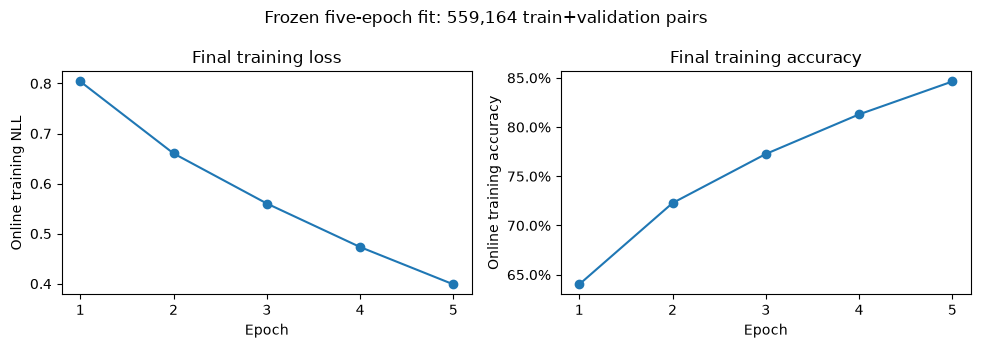

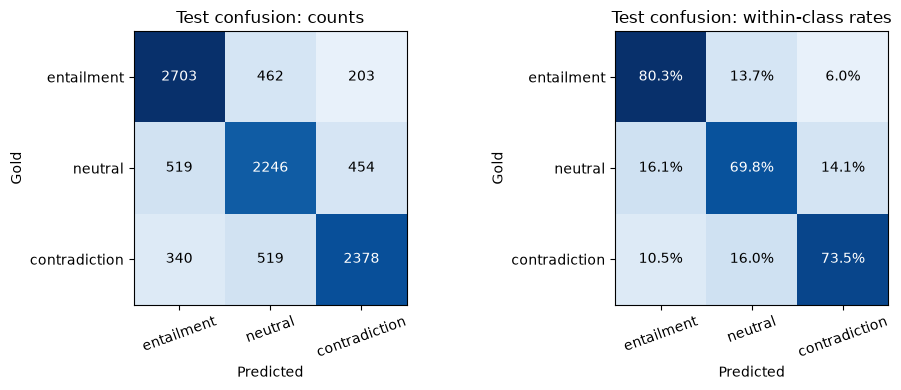

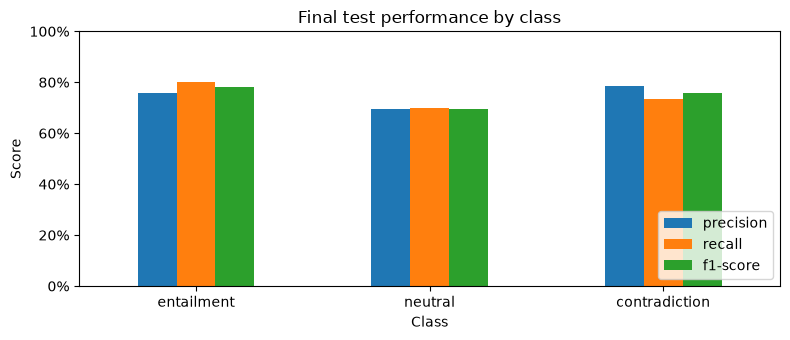

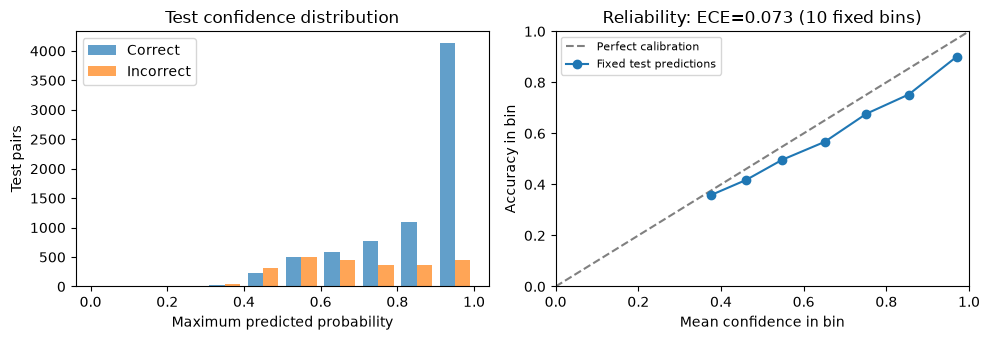

Graphs: /home/borisv/nlp1-student-gp57/part1/results/project1/final/snli_5k_unigram_mlp1/figures
Frozen recipe and schedule remain unchanged after test.


In [42]:
if (final_directory / "manifest.json").exists():
    final_plots, final_ece = plot_final_results(final_directory, final_manifest, final_predictions)
    print("Graphs:", final_plots)
    print("Frozen recipe and schedule remain unchanged after test.")


### Final result and limits

The frozen pipeline achieves **74.58% test accuracy**, **0.7451
macro-F1** and **0.6886 NLL**. All five epochs on **559,164** eligible
train+validation pairs finished in **2.98 minutes**, including fresh
preprocessing, saving and raw-text reload verification. A single prediction pass
covers all **9,824** cleaned official test rows. Later executions verify the saved
probabilities and regenerate plots; they do not train or select another model.

Training curves use online batch statistics. The test reliability plot is a
post-evaluation diagnostic (10-bin ECE **0.0728**, mean confidence **81.86%**).
The curve lies below the perfect-calibration diagonal: confidence is higher
than observed correctness across the displayed bins. The mean confidence is
81.86% versus 74.58% accuracy. The frozen model, probability mapping and decision
threshold remain unchanged.
This test score belongs to the final larger-pool/five-epoch fit; differences from
subset CV or validation are not isolated effects of tuning. No updated Bayesian
claim is made from a single final test model. Student review and oral preparation
are the remaining tasks.

## 11. Oral preparation and group review

Explain sentence pair → BPE → sparse features → logits → probabilities → decision
→ evaluation, and distinguish baseline CV, validation selection and final test.
Review the AI-assisted error notes as a group. Prepare up to six optional backup
slides addressing the project questions, and retain sources/assistance records
for the later blog. Interpret the final result as this pipeline's performance,
not as proof that its representation performs full semantic reasoning.

## Sources and reproducibility

- [Project requirements](project.ipynb), [tutorial](tutorial.ipynb), [course method map](COURSE_METHODS.md).
- [SNLI](https://huggingface.co/datasets/stanfordnlp/snli) and [SNLI paper](https://aclanthology.org/D15-1075/).
- [Course practical used for presentation](https://github.com/S-Chaudhuri/uva_nlp1_2025/blob/main/NLP1_2025_Practical_2_%28student%29.ipynb).
- [Benavoli et al.](https://www.jmlr.org/papers/volume18/16-305/16-305.pdf) and the course's correlated-t example.
- [Findings](PROJECT1_FINDINGS.md), [plan](PROJECT1_PLAN.md), [AI assistance](AI_ASSISTANCE.md).

Baseline/search results were generated by the earlier implementation, whose full code is
preserved in [practical_1_details.ipynb](practical_1_details.ipynb). The final fit and test evaluation use the literal streamlined implementation in
this notebook. It also independently checks the saved baseline data,
probabilities, summaries and posteriors. Historical artifacts are never replaced
by a new claim of provenance. All custom functions/classes called here are local
to this notebook; it imports no project helpers and does not execute other files.